# Generación de imágenes de resonancia magnética mediante difusión gaussiana

**Objetivo específico 3:** Desarrollar un modelo de difusión condicionado por plano anatómico, tipo de tumor y máscara tumoral para generar imágenes sintéticas de resonancia magnética cerebral.

Se implementa el entrenamiento de una U-Net condicionada con predicción de velocidad y se generan imágenes sintéticas mediante muestreo DDIM. Se utilizan máscaras tumorales, una representación espacial EDT y las condiciones de tipo de tumor y plano anatómico.


## 1. Bibliotecas y reproducibilidad

Se importan las dependencias y se establecen las semillas aleatorias y el dispositivo de cálculo.


In [1]:
from pathlib import Path
import copy
import json
import hashlib
import math
import random
import re
import shutil
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import distance_transform_edt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("once")

SEED = 42
VALIDATION_SEED = 2026
DIAGNOSTIC_SEED = 31415

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reproducibilidad razonable. benchmark=False evita seleccionar kernels
# distintos entre ejecuciones; deterministic=True puede reducir velocidad.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM total (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


Dispositivo: cuda
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM total (GB): 16.0


## 2. Configuración experimental y directorios

Se definen los hiperparámetros del modelo y las rutas relativas de los datos, recursos compartidos y resultados.


In [2]:
PROFILE = "final"  # "desarrollo" o "final"

def localizar_raiz_repositorio():
    """Localiza la raíz del repositorio a partir del directorio de ejecución."""
    directorio = Path.cwd().resolve()
    for candidato in (directorio, *directorio.parents):
        if (candidato / "notebooks" / "OE3").is_dir():
            return candidato
    raise FileNotFoundError(
        "No se encontró la raíz del repositorio. "
        "Ubicar el notebook en notebooks/OE3/ y ejecutarlo desde el repositorio."
    )


REPO_ROOT = localizar_raiz_repositorio()
DATA_ROOT = REPO_ROOT / "data" / "BRISC2025" / "segmentation_task"
RESULTS_OE2 = REPO_ROOT / "results" / "OE2"
RESULTS_OE3 = REPO_ROOT / "results" / "OE3"

TRAIN_ROOT = DATA_ROOT / "train"
TEST_ROOT = DATA_ROOT / "test"

TRAIN_IMAGES_DIR = TRAIN_ROOT / "images"
TRAIN_MASKS_DIR = TRAIN_ROOT / "masks"
TEST_IMAGES_DIR = TEST_ROOT / "images"
TEST_MASKS_DIR = TEST_ROOT / "masks"

OUTPUT_ROOT = RESULTS_OE3 / "difusion_gaussiana_v3"
ROI_ROOT = RESULTS_OE2 / "preprocesamiento" / "roiOE1_umbral15"
ROI_THRESHOLD = 127

# Partición estratificada compartida con OE2.
COMMON_SPLIT_CSV = (
    RESULTS_OE2 / "particiones" / "brisc_test_validation_test_50_50.csv"
)

# Umbral binario común con OE2.
MASK_THRESHOLD = 127

# ---------------------------------------------------------------
# Perfil
# ---------------------------------------------------------------
if PROFILE == "desarrollo":
    IMAGE_SIZE = 128
    EPOCHS = 35
    BATCH_SIZE = 16
    EDT_RADIUS = 8

elif PROFILE == "final":
    IMAGE_SIZE = 256
    EPOCHS = 150
    BATCH_SIZE = 4
    EDT_RADIUS = 16

else:
    raise ValueError(
        "PROFILE debe ser "
        "'desarrollo' o 'final'."
    )

# ---------------------------------------------------------------
# DataLoader
# ---------------------------------------------------------------
# 0 es la opción más estable en Jupyter sobre Windows.
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"

# ---------------------------------------------------------------
# Modelo
# ---------------------------------------------------------------
BASE_CHANNELS = 96
CHANNEL_MULTS = (1, 2, 4, 4)
NUM_RES_BLOCKS = 2
DROPOUT = 0.10
ATTENTION_LEVELS = (2, 3)
NUM_ATTENTION_HEADS = 4
COND_EMBED_DIM = 64

# ---------------------------------------------------------------
# Difusión
# ---------------------------------------------------------------
TIMESTEPS = 1000
PREDICTION_TYPE = "v_prediction"
MIN_SNR_GAMMA = 5.0
SPATIAL_WEIGHT_BACKGROUND = 1.0
SPATIAL_WEIGHT_BRAIN = 2.0
SPATIAL_WEIGHT_TUMOR = 6.0
NOISE_SCHEDULE = "cosine"

# ---------------------------------------------------------------
# Optimización
# ---------------------------------------------------------------
OPTIMIZER_NAME = "AdamW"
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0
GRAD_ACCUM_STEPS = 1
EMA_DECAY = 0.9999
USE_AMP = DEVICE.type == "cuda"

# ---------------------------------------------------------------
# Guardado y diagnóstico
# ---------------------------------------------------------------
CHECKPOINT_EVERY = 5
DIAGNOSTIC_EVERY = 5
DDIM_STEPS_DIAGNOSTIC = 50
DDIM_ETA_DIAGNOSTIC = 0.0
DIAGNOSTIC_SAMPLE_BATCH_SIZE = 2  # Inferencia de 9 casos en lotes pequeños (GPU 16 GB).
RUN_TRAINING = False  # Habilitar explícitamente para entrenar o reanudar.
AUTO_RESUME = True
RUN_FULL_CONSISTENCY_CHECKS = True

# Si se está reutilizando un entrenamiento realizado con una versión
# anterior del notebook, la sección de recalibración seleccionará el
# mejor checkpoint según pérdida EMA sobre el split común OE2/OE3.
FORCE_REEVALUATE_EMA_CHECKPOINTS = False

# ---------------------------------------------------------------
# Generación posterior
# ---------------------------------------------------------------
DEFAULT_SAMPLER = "ddim"
DDIM_STEPS_PRODUCTION = 200
DDIM_ETA_PRODUCTION = 0.0

# ---------------------------------------------------------------
# Máscaras sintéticas finales del OE2
# ---------------------------------------------------------------
# Este código NO representa "peso del fondo" en general.
# Corresponde a ROI_OUTSIDE_WEIGHT: peso de los píxeles fuera de R_i.
#
# "01" -> 0.10
# "05" -> 0.50
# "10" -> 1.00
OE2_ROI_OUTSIDE_WEIGHT_CODE = "10"

OE2_ROI_OUTSIDE_WEIGHT_VALUES = {
    "01": 0.10,
    "05": 0.50,
    "10": 1.00,
}

if OE2_ROI_OUTSIDE_WEIGHT_CODE not in OE2_ROI_OUTSIDE_WEIGHT_VALUES:
    raise ValueError(
        "OE2_ROI_OUTSIDE_WEIGHT_CODE debe ser "
        "'01', '05' o '10'."
    )

OE2_ROI_OUTSIDE_WEIGHT = (
    OE2_ROI_OUTSIDE_WEIGHT_VALUES[
        OE2_ROI_OUTSIDE_WEIGHT_CODE
    ]
)

OE2_WEIGHT_FOLDER = (
    f"roiOE1_peso{OE2_ROI_OUTSIDE_WEIGHT_CODE}"
)

# Variantes válidas:
#   "sin_suavizado"
#   "suavizado"
OE2_MASK_VARIANT = "suavizado"

if OE2_MASK_VARIANT not in {
    "sin_suavizado",
    "suavizado",
}:
    raise ValueError(
        "OE2_MASK_VARIANT debe ser "
        "'sin_suavizado' o 'suavizado'."
    )

# Código de carpeta. Se evita el punto deliberadamente:
# 075 -> sigma=0.75
# 100 -> sigma=1.00
# 125 -> sigma=1.25
# 200 -> sigma=2.00
OE2_SMOOTHING_CODE = "200"

OE2_SIGMA_BY_CODE = {
    "075": 0.75,
    "100": 1.00,
    "125": 1.25,
    "200": 2.00,
}

if (
    OE2_MASK_VARIANT == "suavizado"
    and OE2_SMOOTHING_CODE not in OE2_SIGMA_BY_CODE
):
    raise ValueError(
        "OE2_SMOOTHING_CODE debe ser uno de "
        f"{sorted(OE2_SIGMA_BY_CODE)}."
    )

OE2_GAUSSIAN_SIGMA = (
    None
    if OE2_MASK_VARIANT == "sin_suavizado"
    else OE2_SIGMA_BY_CODE[
        OE2_SMOOTHING_CODE
    ]
)

OE2_RUN_ROOT = (
    RESULTS_OE2 / "difusion_bernoulli" / "final" / OE2_WEIGHT_FOLDER
)

OE2_FINAL_MASK_ROOT = (
    OE2_RUN_ROOT
    / "mascaras_sinteticas_finales"
)

if OE2_MASK_VARIANT == "sin_suavizado":
    OE2_SYNTHETIC_MASK_DIR = (
        OE2_FINAL_MASK_ROOT
        / "sin_suavizado"
        / "aceptadas"
    )

    OE2_MASK_VARIANT_TAG = Path(
        "sin_suavizado"
    )

else:
    OE2_SYNTHETIC_MASK_DIR = (
        OE2_FINAL_MASK_ROOT
        / f"suavizado{OE2_SMOOTHING_CODE}"
        / "aceptadas"
    )

    OE2_MASK_VARIANT_TAG = Path(
        f"suavizado{OE2_SMOOTHING_CODE}"
    )

OE2_EXPECTED_CONDITION_DIRS = {
    f"{tumor}_{plane}"
    for tumor in ("gl", "me", "pi")
    for plane in ("ax", "co", "sa")
}

# ---------------------------------------------------------------
# Identificación automática del experimento de entrenamiento
# ---------------------------------------------------------------
# Identificador NUEVO de V3 para evitar colisiones entre configuraciones.
# No se reutilizan archivos o estados de entrenamiento de V1.
TRAINING_CONFIG_FOR_ID = {
    "profile": PROFILE,
    "image_size": IMAGE_SIZE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "edt_radius": EDT_RADIUS,
    "base_channels": BASE_CHANNELS,
    "channel_mults": CHANNEL_MULTS,
    "num_res_blocks": NUM_RES_BLOCKS,
    "dropout": DROPOUT,
    "attention_levels": ATTENTION_LEVELS,
    "num_attention_heads": NUM_ATTENTION_HEADS,
    "cond_embed_dim": COND_EMBED_DIM,
    "timesteps": TIMESTEPS,
    "prediction_type": PREDICTION_TYPE,
    "min_snr_gamma": MIN_SNR_GAMMA,
    "spatial_weight_background": SPATIAL_WEIGHT_BACKGROUND,
    "spatial_weight_brain": SPATIAL_WEIGHT_BRAIN,
    "spatial_weight_tumor": SPATIAL_WEIGHT_TUMOR,
    "roi_root": str(ROI_ROOT),
    "roi_threshold": ROI_THRESHOLD,
    "noise_schedule": NOISE_SCHEDULE,
    "optimizer": OPTIMIZER_NAME,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "grad_clip_norm": GRAD_CLIP_NORM,
    "grad_accum_steps": GRAD_ACCUM_STEPS,
    "ema_decay": EMA_DECAY,
    "seed": SEED,
}

training_config_json = json.dumps(
    TRAINING_CONFIG_FOR_ID,
    sort_keys=True,
    default=list,
)

TRAINING_CONFIG_HASH = hashlib.sha1(
    training_config_json.encode("utf-8")
).hexdigest()[:8]


def comprobar_configuracion_checkpoint(config_guardada, origen="checkpoint"):
    """Comprueba la configuración científica, sin depender de rutas locales."""
    if config_guardada.get("version") != "OE3_V3":
        raise RuntimeError(f"Versión de modelo incompatible en {origen}.")

    discrepancias = []
    for clave, valor_actual in TRAINING_CONFIG_FOR_ID.items():
        if clave == "roi_root":
            continue  # La ubicación del archivo no modifica el experimento.
        if clave not in config_guardada:
            discrepancias.append(clave)
            continue
        valor_guardado = config_guardada[clave]
        if json.dumps(valor_actual, sort_keys=True, default=list) != json.dumps(
            valor_guardado, sort_keys=True, default=list
        ):
            discrepancias.append(clave)

    if discrepancias:
        raise RuntimeError(
            f"Configuración científica incompatible en {origen}: "
            + ", ".join(discrepancias)
        )

PROFILE_TAG = (
    f"{PROFILE}_{IMAGE_SIZE}px"
)

MODEL_TAG = (
    f"snr{MIN_SNR_GAMMA:g}"
    f"_W{SPATIAL_WEIGHT_BACKGROUND:g},"
    f"{SPATIAL_WEIGHT_BRAIN:g},"
    f"{SPATIAL_WEIGHT_TUMOR:g}"
)

# ---------------------------------------------------------------
# Jerarquía de resultados
# ---------------------------------------------------------------
TRAINING_ROOT = OUTPUT_ROOT
EXPERIMENT_DIR = OUTPUT_ROOT / MODEL_TAG
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
LOG_DIR = EXPERIMENT_DIR / "logs"
FIGURE_DIR = EXPERIMENT_DIR / "graficos_entrenamiento"
SAMPLE_DIR = EXPERIMENT_DIR / "muestras_entrenamiento"
CONFIG_DIR = EXPERIMENT_DIR / "configuracion"
GENERATION_ROOT = EXPERIMENT_DIR / "pruebas_muestreo_DDIM"
FINAL_IMAGES_DIR = EXPERIMENT_DIR / "imagenes_sinteticas"  # Reservada para OE4 / generación final.

for directory in (OUTPUT_ROOT, EXPERIMENT_DIR, CHECKPOINT_DIR, LOG_DIR,
                  FIGURE_DIR, SAMPLE_DIR, CONFIG_DIR, GENERATION_ROOT):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    **TRAINING_CONFIG_FOR_ID,
    "mask_threshold":
        MASK_THRESHOLD,
    "version": "OE3_V3",
    "spatial_loss_reduction": "per_sample_normalized_weighted_mse",
    "roi_conditioning": False,
    "architecture_change": "base96_attention_levels_2_3",
    "shared_test_split_csv":
        str(COMMON_SPLIT_CSV),
    "training_config_hash":
        TRAINING_CONFIG_HASH,
    "checkpoint_every":
        CHECKPOINT_EVERY,
    "diagnostic_every":
        DIAGNOSTIC_EVERY,
    "ddim_steps_diagnostic":
        DDIM_STEPS_DIAGNOSTIC,
    "ddim_eta_diagnostic":
        DDIM_ETA_DIAGNOSTIC,
    "oe2_roi_outside_weight_code":
        OE2_ROI_OUTSIDE_WEIGHT_CODE,
    "oe2_roi_outside_weight":
        OE2_ROI_OUTSIDE_WEIGHT,
    "oe2_weight_folder":
        OE2_WEIGHT_FOLDER,
    "oe2_mask_variant":
        OE2_MASK_VARIANT,
    "oe2_smoothing_code":
        (
            None
            if OE2_MASK_VARIANT == "sin_suavizado"
            else OE2_SMOOTHING_CODE
        ),
    "oe2_gaussian_sigma":
        OE2_GAUSSIAN_SIGMA,
}

with open(
    CONFIG_DIR / "config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        CONFIG,
        f,
        indent=2,
        ensure_ascii=False,
        default=list,
    )

print(
    json.dumps(
        CONFIG,
        indent=2,
        ensure_ascii=False,
        default=list,
    )
)


{
  "profile": "final",
  "image_size": 256,
  "epochs": 150,
  "batch_size": 4,
  "edt_radius": 16,
  "base_channels": 96,
  "channel_mults": [
    1,
    2,
    4,
    4
  ],
  "num_res_blocks": 2,
  "dropout": 0.1,
  "attention_levels": [
    2,
    3
  ],
  "num_attention_heads": 4,
  "cond_embed_dim": 64,
  "timesteps": 1000,
  "prediction_type": "v_prediction",
  "min_snr_gamma": 5.0,
  "spatial_weight_background": 1.0,
  "spatial_weight_brain": 2.0,
  "spatial_weight_tumor": 6.0,
  "roi_root": "K:\\Tesis\\Github\\results\\OE2\\preprocesamiento\\roiOE1_umbral15",
  "roi_threshold": 127,
  "noise_schedule": "cosine",
  "optimizer": "AdamW",
  "learning_rate": 0.0002,
  "weight_decay": 0.0001,
  "grad_clip_norm": 1.0,
  "grad_accum_steps": 1,
  "ema_decay": 0.9999,
  "seed": 42,
  "mask_threshold": 127,
  "version": "OE3_V3",
  "spatial_loss_reduction": "per_sample_normalized_weighted_mse",
  "roi_conditioning": false,
  "architecture_change": "base96_attention_levels_2_3",
  "shar

In [3]:
print("PROFILE:", PROFILE)
print("IMAGE_SIZE:", IMAGE_SIZE)
print("EDT_RADIUS:", EDT_RADIUS)
print("MASK_THRESHOLD:", MASK_THRESHOLD)
print("TRAINING_CONFIG_HASH:", TRAINING_CONFIG_HASH)
print("OUTPUT_ROOT:", OUTPUT_ROOT)
print("EXPERIMENT_DIR:", EXPERIMENT_DIR)
print("CHECKPOINT_DIR:", CHECKPOINT_DIR)
print("GENERATION_ROOT:", GENERATION_ROOT)

print("\nSplit compartido OE2/OE3:")
print(" ", COMMON_SPLIT_CSV)

print("\nOrigen de máscaras OE2:")
print(
    "  ROI_OUTSIDE_WEIGHT:",
    OE2_ROI_OUTSIDE_WEIGHT,
)
print(
    "  Carpeta de peso:",
    OE2_WEIGHT_FOLDER,
)
print(
    "  Variante:",
    OE2_MASK_VARIANT,
)
print(
    "  Código suavizado:",
    (
        None
        if OE2_MASK_VARIANT == "sin_suavizado"
        else OE2_SMOOTHING_CODE
    ),
)
print(
    "  Sigma gaussiano:",
    OE2_GAUSSIAN_SIGMA,
)
print(
    "  Ruta:",
    OE2_SYNTHETIC_MASK_DIR,
)

print("PREDICTION_TYPE:", PREDICTION_TYPE)
print("MIN_SNR_GAMMA:", MIN_SNR_GAMMA)
print("PESOS FONDO/ROI/TUMOR:", SPATIAL_WEIGHT_BACKGROUND, SPATIAL_WEIGHT_BRAIN, SPATIAL_WEIGHT_TUMOR)
print("ROI_ROOT:", ROI_ROOT)


PROFILE: final
IMAGE_SIZE: 256
EDT_RADIUS: 16
MASK_THRESHOLD: 127
TRAINING_CONFIG_HASH: 608f8462
OUTPUT_ROOT: K:\Tesis\Github\results\OE3\difusion_gaussiana_v3
EXPERIMENT_DIR: K:\Tesis\Github\results\OE3\difusion_gaussiana_v3\snr5_W1,2,6
CHECKPOINT_DIR: K:\Tesis\Github\results\OE3\difusion_gaussiana_v3\snr5_W1,2,6\checkpoints
GENERATION_ROOT: K:\Tesis\Github\results\OE3\difusion_gaussiana_v3\snr5_W1,2,6\pruebas_muestreo_DDIM

Split compartido OE2/OE3:
  K:\Tesis\Github\results\OE2\particiones\brisc_test_validation_test_50_50.csv

Origen de máscaras OE2:
  ROI_OUTSIDE_WEIGHT: 1.0
  Carpeta de peso: roiOE1_peso10
  Variante: suavizado
  Código suavizado: 200
  Sigma gaussiano: 2.0
  Ruta: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso10\mascaras_sinteticas_finales\suavizado200\aceptadas
PREDICTION_TYPE: v_prediction
MIN_SNR_GAMMA: 5.0
PESOS FONDO/ROI/TUMOR: 1.0 2.0 6.0
ROI_ROOT: K:\Tesis\Github\results\OE2\preprocesamiento\roiOE1_umbral15


## 3. Indexación de los pares BRISC

Se identifican las imágenes, máscaras y condiciones correspondientes al conjunto depurado.


In [4]:
FILENAME_RE = re.compile(
    r"^brisc2025_(train|test)_(\d+)_(gl|me|pi)_(ax|co|sa)_t1$",
    flags=re.IGNORECASE,
)

TUMOR_TO_ID = {"gl": 0, "me": 1, "pi": 2}
PLANE_TO_ID = {"ax": 0, "co": 1, "sa": 2}
ID_TO_TUMOR = {v: k for k, v in TUMOR_TO_ID.items()}
ID_TO_PLANE = {v: k for k, v in PLANE_TO_ID.items()}


def parse_brisc_stem(stem):
    match = FILENAME_RE.match(stem)
    if match is None:
        raise ValueError(f"Nombre BRISC no reconocido: {stem}")
    split, index, tumor_code, plane_code = match.groups()
    return {
        "official_split": split.lower(),
        "index": int(index),
        "tumor_code": tumor_code.lower(),
        "plane_code": plane_code.lower(),
    }


def build_pair_dataframe(images_dir, masks_dir):
    image_files = {
        p.stem: p for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    }
    mask_files = {
        p.stem: p for p in masks_dir.iterdir()
        if p.is_file() and p.suffix.lower() == ".png"
    }

    shared = sorted(set(image_files) & set(mask_files))
    only_images = sorted(set(image_files) - set(mask_files))
    only_masks = sorted(set(mask_files) - set(image_files))

    if only_images or only_masks:
        print(f"Advertencia: imágenes sin máscara: {len(only_images)}")
        print(f"Advertencia: máscaras sin imagen: {len(only_masks)}")

    records = []
    for stem in shared:
        meta = parse_brisc_stem(stem)
        records.append({
            **meta,
            "stem": stem,
            "image_path": str(image_files[stem]),
            "mask_path": str(mask_files[stem]),
            "stratum": f"{meta['tumor_code']}_{meta['plane_code']}",
        })

    return pd.DataFrame(records)


for required_dir in [TRAIN_IMAGES_DIR, TRAIN_MASKS_DIR, TEST_IMAGES_DIR, TEST_MASKS_DIR]:
    if not required_dir.exists():
        raise FileNotFoundError(
            f"No existe {required_dir}. Verificar los directorios de entrada en data/BRISC2025."
        )

train_official_df = build_pair_dataframe(TRAIN_IMAGES_DIR, TRAIN_MASKS_DIR)
test_official_df = build_pair_dataframe(TEST_IMAGES_DIR, TEST_MASKS_DIR)

print("Pares train oficial:", len(train_official_df))
print("Pares test oficial:", len(test_official_df))
display(train_official_df.head())


Pares train oficial: 3792
Pares test oficial: 840


,official_split,index,tumor_code,plane_code,stem,image_path,mask_path,stratum
0,train,1,gl,ax,brisc2025_train_00001_gl_ax_t1,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,gl_ax
1,train,2,gl,ax,brisc2025_train_00002_gl_ax_t1,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,gl_ax
2,train,3,gl,ax,brisc2025_train_00003_gl_ax_t1,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,gl_ax
3,train,4,gl,ax,brisc2025_train_00004_gl_ax_t1,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,gl_ax
4,train,5,gl,ax,brisc2025_train_00005_gl_ax_t1,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,gl_ax


## 4. Partición de validación y prueba final

Se reutiliza la partición estratificada definida en OE2, sin incorporar el conjunto de prueba final al entrenamiento ni a la selección.


In [5]:
SHARED_SPLIT_FILE = COMMON_SPLIT_CSV

if not SHARED_SPLIT_FILE.exists():
    raise FileNotFoundError(
        "No existe el split compartido OE2/OE3:\n"
        f"{SHARED_SPLIT_FILE}\n\n"
        "Ejecuta primero en OE2 la celda que crea "
        "brisc_test_validation_test_50_50.csv."
    )

split_df = pd.read_csv(
    SHARED_SPLIT_FILE
)

required_split_columns = {
    "basename",
    "tumor_code",
    "plane_code",
    "condition",
    "split",
}

missing_split_columns = (
    required_split_columns
    - set(split_df.columns)
)

if missing_split_columns:
    raise RuntimeError(
        "El split compartido no contiene las columnas: "
        f"{sorted(missing_split_columns)}"
    )

expected_stems = set(
    test_official_df["stem"]
)

saved_stems = set(
    split_df["basename"].astype(str)
)

if expected_stems != saved_stems:
    only_brisc = sorted(
        expected_stems - saved_stems
    )[:10]

    only_split = sorted(
        saved_stems - expected_stems
    )[:10]

    raise RuntimeError(
        "El split compartido no coincide exactamente "
        "con el BRISC test indexado por OE3.\n"
        f"Solo en BRISC: {only_brisc}\n"
        f"Solo en CSV: {only_split}"
    )

valid_split_labels = {
    "validation",
    "test_final",
}

found_split_labels = set(
    split_df["split"].astype(str)
)

if not found_split_labels.issubset(
    valid_split_labels
):
    raise RuntimeError(
        "Etiquetas de split no reconocidas: "
        f"{sorted(found_split_labels)}"
    )

assignment = (
    split_df[
        [
            "basename",
            "split",
        ]
    ]
    .rename(
        columns={
            "basename": "stem",
            "split": "oe3_split",
        }
    )
)

test_split_df = (
    test_official_df
    .merge(
        assignment,
        on="stem",
        how="left",
        validate="one_to_one",
    )
)

if test_split_df["oe3_split"].isna().any():
    raise RuntimeError(
        "Existen observaciones del test oficial "
        "sin asignación en el split compartido."
    )

val_df = test_split_df.loc[
    test_split_df["oe3_split"]
    == "validation"
].copy()

test_final_df = test_split_df.loc[
    test_split_df["oe3_split"]
    == "test_final"
].copy()

train_df = train_official_df.copy()

print(
    "Se reutilizó el split compartido:",
    SHARED_SPLIT_FILE,
)
print("Train OE3:", len(train_df))
print("Validation OE3:", len(val_df))
print(
    "Test final reservado:",
    len(test_final_df),
)

split_summary = pd.concat([
    train_df.assign(
        oe3_split="train"
    ),
    val_df,
    test_final_df,
]).groupby(
    [
        "oe3_split",
        "tumor_code",
        "plane_code",
    ]
).size().unstack(
    fill_value=0
)

display(split_summary)


Se reutilizó el split compartido: K:\Tesis\Github\results\OE2\particiones\brisc_test_validation_test_50_50.csv
Train OE3: 3792
Validation OE3: 420
Test final reservado: 420


plane_code              ax   co   sa
oe3_split  tumor_code               
test_final gl           42   40   44
           me           62   41   41
           pi           62   45   43
train      gl          394  430  323
           me          348  400  458
           pi          424  502  513
validation gl           42   40   44
           me           62   40   42
           pi           62   45   43

## 5. Incorporación de regiones válidas

Se asocian a las observaciones las regiones válidas preprocesadas mediante el umbral de intensidad 15.


In [6]:
# Las ROI fueron verificadas previamente en el notebook de integración OE3 V3.
# Aquí solo se emparejan por identificador; no se recalculan.
ROI_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".npy", ".npz"}
BRISC_ID_RE = re.compile(
    r"brisc2025_(train|test)_(\d+)_(gl|me|pi)_(ax|co|sa)_t1",
    flags=re.IGNORECASE,
)


def roi_key(filename):
    match = BRISC_ID_RE.search(str(filename))
    return match.group(0).lower() if match else None


def index_existing_roi_files(root):
    if not root.is_dir():
        raise FileNotFoundError(f"No existe el directorio de ROI del OE1: {root}")
    files = {}
    for path in sorted(root.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in ROI_EXTENSIONS:
            continue
        key = roi_key(path.stem)
        if key is None:
            continue
        if key in files:
            raise RuntimeError(f"ROI duplicada para {key}: {files[key]} y {path}")
        files[key] = path
    return files


roi_files = index_existing_roi_files(ROI_ROOT)
for frame_name, frame in [("train", train_df), ("validation", val_df)]:
    frame["roi_path"] = frame["stem"].str.lower().map(
        lambda stem: str(roi_files[stem]) if stem in roi_files else None
    )
    missing = frame.loc[frame["roi_path"].isna(), "stem"].tolist()
    if missing:
        raise RuntimeError(
            f"Faltan {len(missing)} ROI en {frame_name}; ejemplos: {missing[:8]}. "
            "No se fabricarán ROI automáticamente."
        )
    print(f"ROI asociadas {frame_name}: {frame['roi_path'].notna().sum()}/{len(frame)}")

# Un solo manifiesto, sin leer ni incluir imágenes de test_final.
roi_manifest = pd.concat(
    [train_df.assign(oe3_split="train"), val_df.assign(oe3_split="validation")],
    ignore_index=True,
)
roi_manifest.to_csv(EXPERIMENT_DIR / "manifest_roi_train_validation.csv", index=False)
print("Test final no utilizado para cargar ROI.")

ROI asociadas train: 3792/3792
ROI asociadas validation: 420/420
Test final no utilizado para cargar ROI.


## 6. Transformada de distancia euclidiana con signo

Se construye la representación espacial normalizada de la máscara tumoral mediante EDT.


In [7]:
def compute_signed_edt(mask_binary, radius):
    """
    mask_binary: np.ndarray 2D con valores {0, 1}.
    Retorna Signed Euclidean Distance Transform truncada y normalizada a [-1, 1].
    """
    mask_binary = (mask_binary > 0).astype(np.uint8)

    if mask_binary.max() == 0:
        raise ValueError("No se puede calcular Signed EDT de una máscara vacía.")

    dist_inside = distance_transform_edt(mask_binary)
    dist_outside = distance_transform_edt(1 - mask_binary)
    signed = dist_inside - dist_outside

    signed = np.clip(signed, -radius, radius) / float(radius)
    return signed.astype(np.float32)


## 7. Conjunto de datos y preprocesamiento

Se redimensionan las imágenes y máscaras, se normalizan las intensidades y se preparan los canales de condicionamiento.


In [8]:
def read_roi_image(path):
    """Carga ROI 2D ya generada (imagen o arreglo NumPy), sin modificar el umbral 15 de OE1."""
    path = Path(path)
    ext = path.suffix.lower()
    if ext == ".npy":
        array = np.load(path, allow_pickle=False)
    elif ext == ".npz":
        with np.load(path, allow_pickle=False) as archive:
            key = "roi" if "roi" in archive.files else (archive.files[0] if len(archive.files) == 1 else None)
            if key is None:
                raise ValueError(f"NPZ sin clave ROI identificable: {path}")
            array = archive[key]
    else:
        with Image.open(path) as im:
            array = np.asarray(im.convert("L"))
    array = np.squeeze(array)
    if array.ndim != 2 or not np.isfinite(array).all():
        raise ValueError(f"ROI inválida en {path}: {array.shape}")
    return array


def resize_roi_nearest(array, size):
    if array.shape == (size, size):
        return array
    with Image.fromarray(array.astype(np.float32), mode="F") as im:
        return np.asarray(im.resize((size, size), Image.Resampling.NEAREST))


class BRISCOE3Dataset(Dataset):
    def __init__(self, dataframe, image_size, edt_radius):
        self.df = dataframe.reset_index(drop=True).copy()
        if "roi_path" not in self.df.columns or self.df["roi_path"].isna().any():
            raise ValueError("El Dataset V3 requiere ROI asociada para cada MRI.")
        self.image_size = int(image_size)
        self.edt_radius = int(edt_radius)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["image_path"]) as im:
            image = im.convert("L").resize(
                (self.image_size, self.image_size), Image.Resampling.BILINEAR
            )
            image_np = np.asarray(image, dtype=np.float32) / 127.5 - 1.0
        with Image.open(row["mask_path"]) as im:
            mask = im.convert("L").resize(
                (self.image_size, self.image_size), Image.Resampling.NEAREST
            )
            mask_np = (np.asarray(mask) > MASK_THRESHOLD).astype(np.float32)
        roi_raw = read_roi_image(row["roi_path"])
        roi_np = (resize_roi_nearest(roi_raw, self.image_size) > ROI_THRESHOLD).astype(np.float32)
        edt_np = compute_signed_edt(mask_np, self.edt_radius)

        return {
            "image": torch.from_numpy(image_np.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask_np.copy()).unsqueeze(0),
            "edt": torch.from_numpy(edt_np.copy()).unsqueeze(0),
            "roi": torch.from_numpy(roi_np.copy()).unsqueeze(0),
            "tumor_id": torch.tensor(TUMOR_TO_ID[row["tumor_code"]], dtype=torch.long),
            "plane_id": torch.tensor(PLANE_TO_ID[row["plane_code"]], dtype=torch.long),
            "tumor_code": row["tumor_code"],
            "plane_code": row["plane_code"],
            "stem": row["stem"],
        }


train_dataset = BRISCOE3Dataset(train_df, IMAGE_SIZE, EDT_RADIUS)
val_dataset = BRISCOE3Dataset(val_df, IMAGE_SIZE, EDT_RADIUS)
# No se construye test_final_dataset en V3: permanece completamente reservado.
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False,
)
print("Batches train:", len(train_loader))
print("Batches validation:", len(val_loader))
print("Test final reservado (solo índice):", len(test_final_df))

Batches train: 948
Batches validation: 105
Test final reservado (solo índice): 420


## 8. Verificación de consistencia

Se comprueba la integridad de los pares, las particiones y las dimensiones requeridas por el modelo.


In [9]:
def run_dataframe_checks(train_df, val_df, test_df):
    train_stems = set(train_df["stem"])
    val_stems = set(val_df["stem"])
    test_stems = set(test_df["stem"])

    assert train_stems.isdisjoint(val_stems)
    assert train_stems.isdisjoint(test_stems)
    assert val_stems.isdisjoint(test_stems)

    expected_strata = {f"{t}_{p}" for t in TUMOR_TO_ID for p in PLANE_TO_ID}
    for name, df in [("train", train_df), ("validation", val_df), ("test_final", test_df)]:
        missing = expected_strata - set(df["stratum"])
        if missing:
            raise RuntimeError(f"{name} no contiene los estratos: {sorted(missing)}")

    print("DataFrames: OK")


def run_dataset_checks(dataset, name, full=True):
    indices = range(len(dataset)) if full else np.linspace(
        0, len(dataset) - 1, min(50, len(dataset)), dtype=int
    )

    empty_masks = []
    bad_shapes = []
    bad_ranges = []
    nan_cases = []

    iterator = tqdm(indices, desc=f"Chequeando {name}") if full else indices

    for idx in iterator:
        item = dataset[idx]
        x, m, d, r = item["image"], item["mask"], item["edt"], item["roi"]

        expected_shape = (1, IMAGE_SIZE, IMAGE_SIZE)
        if tuple(x.shape) != expected_shape or tuple(m.shape) != expected_shape or tuple(d.shape) != expected_shape or tuple(r.shape) != expected_shape:
            bad_shapes.append(item["stem"])

        if m.sum().item() <= 0:
            empty_masks.append(item["stem"])

        unique_mask = set(torch.unique(m).tolist())
        if not unique_mask.issubset({0.0, 1.0}) or not set(torch.unique(r).tolist()).issubset({0.0, 1.0}):
            bad_ranges.append(item["stem"])

        if x.min() < -1.0001 or x.max() > 1.0001 or d.min() < -1.0001 or d.max() > 1.0001:
            bad_ranges.append(item["stem"])

        if not torch.isfinite(x).all() or not torch.isfinite(m).all() or not torch.isfinite(d).all() or not torch.isfinite(r).all():
            nan_cases.append(item["stem"])

    problems = {
        "empty_masks": empty_masks,
        "bad_shapes": bad_shapes,
        "bad_ranges": bad_ranges,
        "nan_cases": nan_cases,
    }

    if any(len(v) > 0 for v in problems.values()):
        raise RuntimeError(f"Problemas en {name}: {problems}")

    print(f"{name}: OK ({len(dataset)} observaciones)")


run_dataframe_checks(train_df, val_df, test_final_df)
run_dataset_checks(train_dataset, "train", full=RUN_FULL_CONSISTENCY_CHECKS)
run_dataset_checks(val_dataset, "validation", full=RUN_FULL_CONSISTENCY_CHECKS)

# El test final no se inspecciona píxel a píxel en OE3 para mantenerlo reservado.
# Solo se validó arriba la estructura de su DataFrame y presencia de estratos.


DataFrames: OK


Chequeando train:   0%|          | 0/3792 [00:00<?, ?it/s]

train: OK (3792 observaciones)


Chequeando validation:   0%|          | 0/420 [00:00<?, ?it/s]

validation: OK (420 observaciones)


## 9. Visualización del preprocesamiento

Se presentan ejemplos de imágenes, máscaras tumorales y representaciones auxiliares.


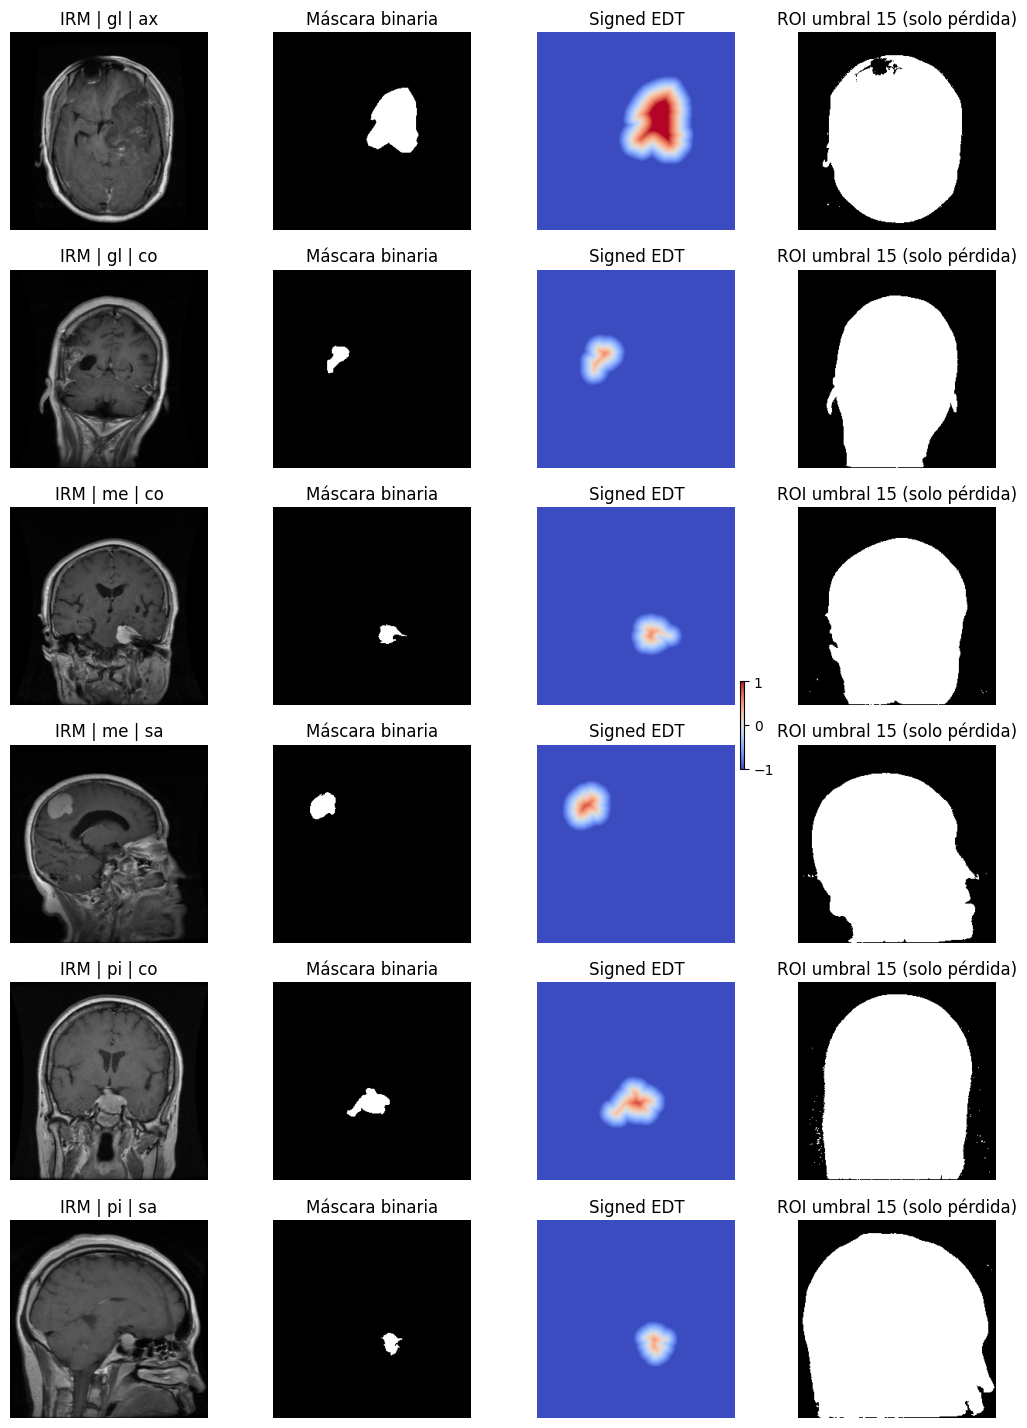

In [10]:
def denormalize_image(x):
    return ((x.clamp(-1, 1) + 1.0) * 127.5).round().to(torch.uint8)


def show_preprocessing_examples(dataset, n=6):
    n = min(n, len(dataset))
    indices = np.linspace(0, len(dataset) - 1, n, dtype=int)

    fig, axes = plt.subplots(n, 4, figsize=(13, 3 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, idx in enumerate(indices):
        item = dataset[idx]
        image = item["image"].squeeze().numpy()
        mask = item["mask"].squeeze().numpy()
        edt = item["edt"].squeeze().numpy()
        roi = item["roi"].squeeze().numpy()

        axes[row_idx, 0].imshow(image, cmap="gray", vmin=-1, vmax=1)
        axes[row_idx, 0].set_title(f"IRM | {item['tumor_code']} | {item['plane_code']}")
        axes[row_idx, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[row_idx, 1].set_title("Máscara binaria")
        im = axes[row_idx, 2].imshow(edt, cmap="coolwarm", vmin=-1, vmax=1)
        axes[row_idx, 2].set_title("Signed EDT")
        axes[row_idx, 3].imshow(roi, cmap="gray", vmin=0, vmax=1)
        axes[row_idx, 3].set_title("ROI umbral 15 (solo pérdida)")

        for ax in axes[row_idx]:
            ax.axis("off")

    fig.colorbar(im, ax=axes[:, 2].tolist(), fraction=0.02, pad=0.02)
    plt.show()


show_preprocessing_examples(train_dataset, n=6)


## 10. Proceso de difusión gaussiana

Se implementan el calendario coseno y las transformaciones correspondientes a la predicción de velocidad.


In [11]:
def cosine_beta_schedule(timesteps, s=0.008):
    steps = timesteps + 1
    x = torch.linspace(0, timesteps, steps, dtype=torch.float64)
    alphas_cumprod = torch.cos(((x / timesteps) + s) / (1 + s) * math.pi * 0.5) ** 2
    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
    betas = 1.0 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return betas.clamp(1e-5, 0.999).float()


betas = cosine_beta_schedule(TIMESTEPS).to(DEVICE)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)

posterior_variance = (
    betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)
).clamp(min=1e-20)


def extract(a, t, x_shape):
    out = a.gather(0, t)
    return out.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))


def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    return (
        extract(sqrt_alphas_cumprod, t, x0.shape) * x0
        + extract(sqrt_one_minus_alphas_cumprod, t, x0.shape) * noise
    )


def predict_v_target(x0, noise, t):
    a = extract(sqrt_alphas_cumprod, t, x0.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, x0.shape)
    return a * noise - b * x0


def predict_x0_from_v(xt, t, v):
    a = extract(sqrt_alphas_cumprod, t, xt.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, xt.shape)
    return a * xt - b * v


def predict_eps_from_v(xt, t, v):
    a = extract(sqrt_alphas_cumprod, t, xt.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, xt.shape)
    return b * xt + a * v


def eps_from_x0(xt, t, x0):
    a = extract(sqrt_alphas_cumprod, t, xt.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, xt.shape)
    return (xt - a * x0) / b.clamp(min=1e-12)


SNR_BY_TIMESTEP = alphas_cumprod.double() / (1.0 - alphas_cumprod.double()).clamp_min(1e-20)
MIN_SNR_WEIGHT_BY_TIMESTEP = (
    torch.clamp(SNR_BY_TIMESTEP, max=MIN_SNR_GAMMA) / (1.0 + SNR_BY_TIMESTEP)
).float()


# Identidades de v-prediction: comprobar en varios timesteps, incluidos extremos.
with torch.no_grad():
    x_test = torch.rand((5, 1, 8, 8), device=DEVICE) * 2 - 1
    e_test = torch.randn_like(x_test)
    t_test = torch.tensor([0, 1, 100, 500, TIMESTEPS - 1], device=DEVICE)
    xt_test = q_sample(x_test, t_test, e_test)
    v_test = predict_v_target(x_test, e_test, t_test)
    torch.testing.assert_close(predict_x0_from_v(xt_test, t_test, v_test), x_test, atol=2e-5, rtol=2e-5)
    torch.testing.assert_close(predict_eps_from_v(xt_test, t_test, v_test), e_test, atol=2e-5, rtol=2e-5)
    assert torch.isfinite(MIN_SNR_WEIGHT_BY_TIMESTEP).all()
print("Identidades de v-prediction y Min-SNR: OK")


Identidades de v-prediction y Min-SNR: OK


## 11. Ponderación temporal y espacial

Se implementa Min-SNR con $\gamma=5$ y se asignan pesos de 1, 2 y 6 al fondo exterior, región válida no tumoral y tumor, respectivamente.


In [12]:
def build_spatial_weight_map(mask, roi):
    """Regiones excluyentes: tumor prioritario, ROI sin tumor y fondo."""
    tumor = mask > 0.5
    brain = (roi > 0.5) & ~tumor
    background = ~(tumor | brain)
    weights = torch.where(
        tumor,
        SPATIAL_WEIGHT_TUMOR,
        torch.where(brain, SPATIAL_WEIGHT_BRAIN, SPATIAL_WEIGHT_BACKGROUND),
    ).to(dtype=torch.float32)
    return weights, {"tumor": tumor, "roi_sin_tumor": brain, "fondo": background}


def weighted_v_loss(v_pred, v_target, t, mask, roi):
    """Pérdida final Min-SNR sobre MSE espacial, por muestra; cálculos float32."""
    if v_pred.shape != v_target.shape or mask.shape != v_target.shape or roi.shape != v_target.shape:
        raise ValueError("Predicción, objetivo, máscara y ROI deben compartir shape [B,1,H,W]")
    weights, regions = build_spatial_weight_map(mask, roi)
    err = (v_pred.float() - v_target.float()).square()
    numerator = (err * weights).sum(dim=(1, 2, 3))
    denominator = weights.sum(dim=(1, 2, 3)).clamp_min(1e-8)
    spatial_mse = numerator / denominator
    timestep_weight = MIN_SNR_WEIGHT_BY_TIMESTEP.gather(0, t)
    weighted = timestep_weight * spatial_mse
    return weighted.mean(), {
        "mse_v_global": err.mean().detach(),
        "mse_v_espacial": spatial_mse.mean().detach(),
        "min_snr_peso_promedio": timestep_weight.mean().detach(),
    }


# Controles sin dependencia del dataset: pesos, prioridad tumoral y reducción.
with torch.no_grad():
    m = torch.zeros((2, 1, 4, 4), device=DEVICE)
    r = torch.zeros_like(m)
    m[:, :, 1, 1] = 1
    r[:, :, :2, :2] = 1
    r[:, :, 1, 1] = 0  # Tumor fuera de ROI: prioridad del tumor.
    W, regions = build_spatial_weight_map(m, r)
    assert float(W[0, 0, 1, 1]) == SPATIAL_WEIGHT_TUMOR
    assert float(W[0, 0, 0, 0]) == SPATIAL_WEIGHT_BRAIN
    assert float(W[0, 0, 3, 3]) == SPATIAL_WEIGHT_BACKGROUND
    assert (regions["tumor"].int() + regions["roi_sin_tumor"].int() + regions["fondo"].int() == 1).all()
    t = torch.tensor([10, 500], device=DEVICE)
    loss, metrics = weighted_v_loss(torch.zeros_like(m), torch.ones_like(m), t, m, r)
    assert torch.isfinite(loss) and loss.item() > 0
print("Regiones excluyentes y pérdida V3: OK")

Regiones excluyentes y pérdida V3: OK


### Visualización de los pesos espaciales

Se representa el mapa de ponderación asociado a un ejemplo del conjunto de entrenamiento.


K:\Anaconda3\envs\tesis\Lib\site-packages\matplotlib\cbook.py:684: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)


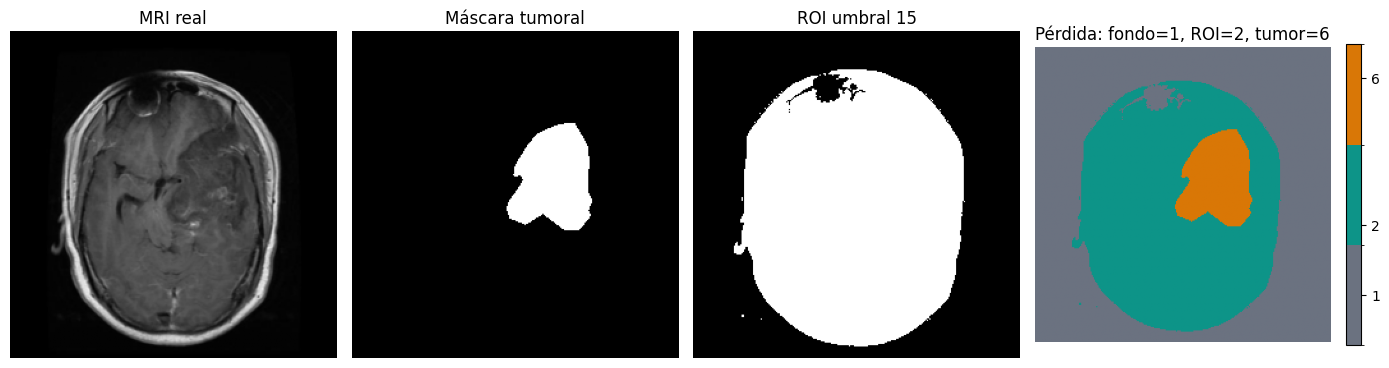

In [13]:
# Solo diagnóstico: no altera datos ni entrenamiento.
from matplotlib.colors import ListedColormap, BoundaryNorm

example_item = train_dataset[0]
example_w, _ = build_spatial_weight_map(
    example_item["mask"].unsqueeze(0),
    example_item["roi"].unsqueeze(0),
)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
axes[0].imshow(example_item["image"].squeeze(), cmap="gray", vmin=-1, vmax=1)
axes[0].set_title("MRI real")
axes[1].imshow(example_item["mask"].squeeze(), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara tumoral")
axes[2].imshow(example_item["roi"].squeeze(), cmap="gray", vmin=0, vmax=1)
axes[2].set_title("ROI umbral 15")
weight_im = axes[3].imshow(
    example_w[0, 0].numpy(), cmap=ListedColormap(["#6b7280", "#0d9488", "#d97706"]),
    norm=BoundaryNorm([0.5, 1.5, 4, 7], 3),
)
axes[3].set_title("Pérdida: fondo=1, ROI=2, tumor=6")
fig.colorbar(weight_im, ax=axes[3], ticks=[1, 2, 6], fraction=0.046)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mapa_ponderacion_v2.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 12. Arquitectura U-Net condicionada

Se define la red convolucional con 96 canales iniciales y mecanismos de autoatención multirresolución.


In [14]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        exponent = -math.log(10000) * torch.arange(
            half, device=t.device, dtype=torch.float32
        ) / max(half - 1, 1)
        frequencies = torch.exp(exponent)
        angles = t.float()[:, None] * frequencies[None, :]
        emb = torch.cat([angles.sin(), angles.cos()], dim=1)
        if self.dim % 2 == 1:
            emb = F.pad(emb, (0, 1))
        return emb


def group_norm(channels):
    groups = min(32, channels)
    while channels % groups != 0:
        groups -= 1
    return nn.GroupNorm(groups, channels)


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, emb_dim, dropout=0.0):
        super().__init__()
        self.norm1 = group_norm(in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.emb_proj = nn.Sequential(
            nn.SiLU(),
            nn.Linear(emb_dim, out_channels),
        )
        self.norm2 = group_norm(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, kernel_size=1)
        )

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(emb)[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)


class SelfAttention2d(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()
        if channels % num_heads != 0:
            raise ValueError("channels debe ser divisible por num_heads")
        self.channels = channels
        self.num_heads = num_heads
        self.head_dim = channels // num_heads
        self.norm = group_norm(channels)
        self.qkv = nn.Conv2d(channels, channels * 3, kernel_size=1)
        self.proj = nn.Conv2d(channels, channels, kernel_size=1)

    def forward(self, x):
        b, c, h, w = x.shape
        residual = x
        x = self.norm(x)
        qkv = self.qkv(x)
        qkv = qkv.view(b, 3, self.num_heads, self.head_dim, h * w)
        q, k, v = qkv.unbind(dim=1)

        # [B, heads, N, head_dim]
        q = q.transpose(-2, -1)
        k = k.transpose(-2, -1)
        v = v.transpose(-2, -1)

        if not hasattr(F, "scaled_dot_product_attention"):
            raise RuntimeError("La atención 64×64 exige PyTorch 2.x con scaled_dot_product_attention")
        out = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=False)

        out = out.transpose(-2, -1).contiguous().view(b, c, h, w)
        return residual + self.proj(out)


class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=4, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2.0, mode="nearest")
        return self.conv(x)


class ConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels=3,
        out_channels=1,
        base_channels=64,
        channel_mults=(1, 2, 4, 4),
        num_res_blocks=2,
        dropout=0.1,
        attention_levels=(3,),
        num_attention_heads=4,
        cond_embed_dim=64,
        num_tumor_classes=3,
        num_plane_classes=3,
    ):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.num_levels = len(channel_mults)
        self.attention_levels = set(attention_levels)

        emb_dim = base_channels * 4
        time_input_dim = base_channels

        self.time_pos_emb = SinusoidalTimeEmbedding(time_input_dim)
        self.time_mlp = nn.Sequential(
            nn.Linear(time_input_dim, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )

        self.tumor_emb = nn.Embedding(num_tumor_classes, cond_embed_dim)
        self.plane_emb = nn.Embedding(num_plane_classes, cond_embed_dim)
        self.semantic_mlp = nn.Sequential(
            nn.Linear(cond_embed_dim * 2, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )

        channels_per_level = [base_channels * mult for mult in channel_mults]
        self.input_conv = nn.Conv2d(in_channels, channels_per_level[0], kernel_size=3, padding=1)

        self.down_levels = nn.ModuleList()
        current_channels = channels_per_level[0]

        for level_idx, out_ch in enumerate(channels_per_level):
            blocks = nn.ModuleList()
            for block_idx in range(num_res_blocks):
                in_ch = current_channels if block_idx == 0 else out_ch
                blocks.append(ResBlock(in_ch, out_ch, emb_dim, dropout))
                current_channels = out_ch

            attention = (
                SelfAttention2d(out_ch, num_attention_heads)
                if level_idx in self.attention_levels
                else nn.Identity()
            )
            downsample = Downsample(out_ch) if level_idx < self.num_levels - 1 else nn.Identity()

            self.down_levels.append(nn.ModuleDict({
                "blocks": blocks,
                "attention": attention,
                "downsample": downsample,
            }))

        self.mid_block1 = ResBlock(current_channels, current_channels, emb_dim, dropout)
        self.mid_attention = SelfAttention2d(current_channels, num_attention_heads)
        self.mid_block2 = ResBlock(current_channels, current_channels, emb_dim, dropout)

        self.up_levels = nn.ModuleList()
        for level_idx in reversed(range(self.num_levels)):
            skip_ch = channels_per_level[level_idx]
            out_ch = channels_per_level[level_idx]

            blocks = nn.ModuleList()
            blocks.append(ResBlock(current_channels + skip_ch, out_ch, emb_dim, dropout))
            current_channels = out_ch
            for _ in range(num_res_blocks - 1):
                blocks.append(ResBlock(current_channels, out_ch, emb_dim, dropout))

            attention = (
                SelfAttention2d(out_ch, num_attention_heads)
                if level_idx in self.attention_levels
                else nn.Identity()
            )
            upsample = Upsample(out_ch) if level_idx > 0 else nn.Identity()

            self.up_levels.append(nn.ModuleDict({
                "blocks": blocks,
                "attention": attention,
                "upsample": upsample,
            }))

        self.out_norm = group_norm(current_channels)
        self.out_conv = nn.Conv2d(current_channels, out_channels, kernel_size=3, padding=1)

    def make_embedding(self, t, tumor_id, plane_id):
        e_t = self.time_mlp(self.time_pos_emb(t))
        e_tumor = self.tumor_emb(tumor_id)
        e_plane = self.plane_emb(plane_id)
        e_sem = self.semantic_mlp(torch.cat([e_tumor, e_plane], dim=1))
        return e_t + e_sem

    def forward(self, xt, mask, edt, t, tumor_id, plane_id):
        x = torch.cat([xt, mask, edt], dim=1)
        emb = self.make_embedding(t, tumor_id, plane_id)

        h = self.input_conv(x)
        skips = []

        for level in self.down_levels:
            for block in level["blocks"]:
                h = block(h, emb)
            h = level["attention"](h)
            skips.append(h)
            h = level["downsample"](h)

        h = self.mid_block1(h, emb)
        h = self.mid_attention(h)
        h = self.mid_block2(h, emb)

        for level in self.up_levels:
            skip = skips.pop()
            if h.shape[-2:] != skip.shape[-2:]:
                raise RuntimeError(f"Shapes incompatibles en skip: {h.shape} vs {skip.shape}")
            h = torch.cat([h, skip], dim=1)
            for block in level["blocks"]:
                h = block(h, emb)
            h = level["attention"](h)
            h = level["upsample"](h)

        return self.out_conv(F.silu(self.out_norm(h)))


## 13. Instanciación y comprobación del modelo

Se inicializa la arquitectura y se comprueban las dimensiones y operaciones de entrenamiento.


In [15]:
model = ConditionalUNet(
    in_channels=3,
    out_channels=1,
    base_channels=BASE_CHANNELS,
    channel_mults=CHANNEL_MULTS,
    num_res_blocks=NUM_RES_BLOCKS,
    dropout=DROPOUT,
    attention_levels=ATTENTION_LEVELS,
    num_attention_heads=NUM_ATTENTION_HEADS,
    cond_embed_dim=COND_EMBED_DIM,
).to(DEVICE)

num_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros totales: {num_params:,}")
print(f"Parámetros entrenables: {trainable_params:,}")

# Smoke test con un batch real pequeño.
batch = next(iter(train_loader))
b = min(2, batch["image"].shape[0])
x0 = batch["image"][:b].to(DEVICE)
mask = batch["mask"][:b].to(DEVICE)
edt = batch["edt"][:b].to(DEVICE)
tumor_id = batch["tumor_id"][:b].to(DEVICE)
plane_id = batch["plane_id"][:b].to(DEVICE)
t = torch.randint(0, TIMESTEPS, (b,), device=DEVICE)
noise = torch.randn_like(x0)
xt = q_sample(x0, t, noise)

with torch.no_grad():
    v_pred = model(xt, mask, edt, t, tumor_id, plane_id)
    v_target = predict_v_target(x0, noise, t)
    loss_smoke, metrics_smoke = weighted_v_loss(v_pred, v_target, t, mask, batch["roi"][:b].to(DEVICE))

print("x0:", tuple(x0.shape))
print("v_pred:", tuple(v_pred.shape))
print("Pérdida V3 smoke:", float(loss_smoke))
assert v_pred.shape == x0.shape
print("Smoke test: OK")

del batch, x0, mask, edt, tumor_id, plane_id, t, noise, xt, v_pred, v_target, loss_smoke, metrics_smoke
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


Parámetros totales: 44,721,313
Parámetros entrenables: 44,721,313
x0: (2, 1, 256, 256)
v_pred: (2, 1, 256, 256)
Pérdida V3 smoke: 0.011301897466182709
Smoke test: OK


## 14. Optimizador y promedio móvil exponencial

Se configuran el algoritmo de optimización y la actualización de parámetros EMA.


In [16]:
ema_model = copy.deepcopy(model).eval()
for param in ema_model.parameters():
    param.requires_grad_(False)


@torch.no_grad()
def update_ema(ema_model, model, decay):
    ema_params = dict(ema_model.named_parameters())
    model_params = dict(model.named_parameters())

    for name, param in model_params.items():
        ema_params[name].mul_(decay).add_(param, alpha=1.0 - decay)

    ema_buffers = dict(ema_model.named_buffers())
    model_buffers = dict(model.named_buffers())
    for name, buffer in model_buffers.items():
        ema_buffers[name].copy_(buffer)


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6,
)

if USE_AMP:
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=True)
    except TypeError:
        scaler = torch.cuda.amp.GradScaler(enabled=True)
else:
    scaler = None

print("AMP:", USE_AMP)


AMP: True


## 15. Procedimientos de muestreo

Se implementan los muestreadores DDPM y DDIM compatibles con la predicción de velocidad.


In [17]:
def randn_per_sample(
    shape,
    device,
    dtype,
    generator=None,
    generators=None,
):
    """
    Genera ruido normal.

    - generator: un único RNG para todo el batch.
    - generators: lista de RNG, uno por muestra.

    generators tiene prioridad cuando se entrega.
    """
    if generators is not None:
        if len(generators) != shape[0]:
            raise ValueError(
                "La cantidad de generators debe coincidir "
                "con el tamaño del batch."
            )

        chunks = []

        for i, sample_generator in enumerate(
            generators
        ):
            sample_shape = (
                1,
                *shape[1:],
            )

            chunks.append(
                torch.randn(
                    sample_shape,
                    device=device,
                    dtype=dtype,
                    generator=sample_generator,
                )
            )

        return torch.cat(
            chunks,
            dim=0,
        )

    return torch.randn(
        shape,
        device=device,
        dtype=dtype,
        generator=generator,
    )


@torch.no_grad()
def p_sample_ddpm(
    model,
    xt,
    mask,
    edt,
    tumor_id,
    plane_id,
    t,
    generator=None,
    generators=None,
):
    v_pred = model(
        xt,
        mask,
        edt,
        t,
        tumor_id,
        plane_id,
    )

    eps_pred = predict_eps_from_v(xt, t, v_pred)

    beta_t = extract(
        betas,
        t,
        xt.shape,
    )

    sqrt_one_minus_ab_t = extract(
        sqrt_one_minus_alphas_cumprod,
        t,
        xt.shape,
    )

    sqrt_recip_alpha_t = extract(
        sqrt_recip_alphas,
        t,
        xt.shape,
    )

    model_mean = (
        sqrt_recip_alpha_t
        * (
            xt
            - beta_t
            * eps_pred
            / sqrt_one_minus_ab_t
        )
    )

    posterior_var_t = extract(
        posterior_variance,
        t,
        xt.shape,
    )

    noise = randn_per_sample(
        xt.shape,
        device=xt.device,
        dtype=xt.dtype,
        generator=generator,
        generators=generators,
    )

    nonzero_mask = (
        (t != 0)
        .float()
        .reshape(
            t.shape[0],
            *((1,) * (xt.ndim - 1)),
        )
    )

    return (
        model_mean
        + nonzero_mask
        * torch.sqrt(
            posterior_var_t
        )
        * noise
    )


@torch.no_grad()
def sample_ddpm(
    model,
    mask,
    edt,
    tumor_id,
    plane_id,
    initial_noise=None,
    generator=None,
    generators=None,
    show_progress=True,
):
    model.eval()

    b = mask.shape[0]

    shape = (
        b,
        1,
        mask.shape[-2],
        mask.shape[-1],
    )

    if initial_noise is None:
        x = randn_per_sample(
            shape,
            device=mask.device,
            dtype=mask.dtype,
            generator=generator,
            generators=generators,
        )
    else:
        x = initial_noise.clone()

    iterator = reversed(
        range(TIMESTEPS)
    )

    if show_progress:
        iterator = tqdm(
            iterator,
            total=TIMESTEPS,
            desc="DDPM sampling",
        )

    for i in iterator:
        t = torch.full(
            (b,),
            i,
            device=mask.device,
            dtype=torch.long,
        )

        x = p_sample_ddpm(
            model,
            x,
            mask,
            edt,
            tumor_id,
            plane_id,
            t,
            generator=generator,
            generators=generators,
        )

    return x.clamp(
        -1,
        1,
    )


@torch.no_grad()
def sample_ddim(
    model,
    mask,
    edt,
    tumor_id,
    plane_id,
    num_steps=50,
    eta=0.0,
    initial_noise=None,
    generator=None,
    generators=None,
    show_progress=True,
):
    model.eval()

    b = mask.shape[0]

    shape = (
        b,
        1,
        mask.shape[-2],
        mask.shape[-1],
    )

    if initial_noise is None:
        x = randn_per_sample(
            shape,
            device=mask.device,
            dtype=mask.dtype,
            generator=generator,
            generators=generators,
        )
    else:
        x = initial_noise.clone()

    if not 2 <= int(num_steps) <= TIMESTEPS:
        raise ValueError(f"num_steps debe estar entre 2 y {TIMESTEPS}")
    if not 0.0 <= float(eta) <= 1.0:
        raise ValueError("eta debe estar entre 0 y 1")
    timesteps = np.linspace(
        0,
        TIMESTEPS - 1,
        num_steps,
        dtype=np.int64,
    )[::-1].copy()

    iterator = timesteps

    if show_progress:
        iterator = tqdm(
            iterator,
            desc="DDIM sampling",
        )

    for idx, i in enumerate(
        iterator
    ):
        t = torch.full(
            (b,),
            int(i),
            device=mask.device,
            dtype=torch.long,
        )

        v_pred = model(
            x,
            mask,
            edt,
            t,
            tumor_id,
            plane_id,
        )

        alpha_bar_t = extract(
            alphas_cumprod,
            t,
            x.shape,
        )

        pred_x0 = predict_x0_from_v(x, t, v_pred).clamp(-1, 1)
        # Clipping coherente: eps se recalcula a partir de x0 truncado.
        eps = eps_from_x0(x, t, pred_x0)

        if idx == len(timesteps) - 1:
            x = pred_x0
            continue

        prev_i = int(
            timesteps[
                idx + 1
            ]
        )

        t_prev = torch.full(
            (b,),
            prev_i,
            device=mask.device,
            dtype=torch.long,
        )

        alpha_bar_prev = extract(
            alphas_cumprod,
            t_prev,
            x.shape,
        )

        sigma = (
            eta
            * torch.sqrt(
                (
                    1.0
                    - alpha_bar_prev
                )
                / (
                    1.0
                    - alpha_bar_t
                )
                * (
                    1.0
                    - alpha_bar_t
                    / alpha_bar_prev
                )
            )
        )

        direction = (
            torch.sqrt(
                torch.clamp(
                    1.0
                    - alpha_bar_prev
                    - sigma**2,
                    min=0.0,
                )
            )
            * eps
        )

        if eta > 0:
            noise = randn_per_sample(
                x.shape,
                device=x.device,
                dtype=x.dtype,
                generator=generator,
                generators=generators,
            )
        else:
            noise = torch.zeros_like(
                x
            )

        x = (
            torch.sqrt(
                alpha_bar_prev
            )
            * pred_x0
            + direction
            + sigma
            * noise
        )

    return x.clamp(
        -1,
        1,
    )


## 16. Casos fijos de diagnóstico

Se seleccionan ejemplos de validación para controlar la evolución del entrenamiento.


In [18]:
def select_fixed_diagnostics(val_df):
    selected_rows = []
    for stratum, group in val_df.sort_values("stem").groupby("stratum"):
        selected_rows.append(group.iloc[0])
    return pd.DataFrame(selected_rows).reset_index(drop=True)


diagnostic_df = select_fixed_diagnostics(val_df)
diagnostic_dataset = BRISCOE3Dataset(diagnostic_df, IMAGE_SIZE, EDT_RADIUS)
diagnostic_loader = DataLoader(
    diagnostic_dataset,
    batch_size=len(diagnostic_dataset),
    shuffle=False,
    num_workers=0,
)

diagnostic_batch_cpu = next(iter(diagnostic_loader))
print("Casos diagnósticos:")
display(diagnostic_df[["stem", "tumor_code", "plane_code", "stratum"]])


Casos diagnósticos:


,stem,tumor_code,plane_code,stratum
0,brisc2025_test_00006_gl_ax_t1,gl,ax,gl_ax
1,brisc2025_test_00089_gl_co_t1,gl,co,gl_co
2,brisc2025_test_00169_gl_sa_t1,gl,sa,gl_sa
3,brisc2025_test_00255_me_ax_t1,me,ax,me_ax
4,brisc2025_test_00392_me_co_t1,me,co,me_co
5,brisc2025_test_00478_me_sa_t1,me,sa,me_sa
6,brisc2025_test_00701_pi_ax_t1,pi,ax,pi_ax
7,brisc2025_test_00826_pi_co_t1,pi,co,pi_co
8,brisc2025_test_00920_pi_sa_t1,pi,sa,pi_sa


## 17. Diagnósticos de reconstrucción y generación

Se definen las funciones que registran reconstrucciones y muestras DDIM durante el entrenamiento.


In [19]:
def save_reconstruction_diagnostic(model, batch_cpu, epoch, output_dir):
    model.eval()

    n = min(3, batch_cpu["image"].shape[0])
    x0 = batch_cpu["image"][:n].to(DEVICE)
    mask = batch_cpu["mask"][:n].to(DEVICE)
    edt = batch_cpu["edt"][:n].to(DEVICE)
    tumor_id = batch_cpu["tumor_id"][:n].to(DEVICE)
    plane_id = batch_cpu["plane_id"][:n].to(DEVICE)

    selected_t = [100, 500, 900]
    generator = torch.Generator(device=DEVICE).manual_seed(DIAGNOSTIC_SEED + 1)
    fixed_noise = torch.randn(x0.shape, device=DEVICE, generator=generator)

    fig, axes = plt.subplots(n, 8, figsize=(20, 3 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        axes[i, 0].imshow(x0[i, 0].detach().cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
        axes[i, 0].set_title("x0 real")
        axes[i, 1].imshow(mask[i, 0].detach().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("máscara")

    col = 2
    with torch.no_grad():
        for t_value in selected_t:
            t = torch.full((n,), t_value, device=DEVICE, dtype=torch.long)
            xt = q_sample(x0, t, fixed_noise)
            v_pred = model(xt, mask, edt, t, tumor_id, plane_id)
            x0_hat = predict_x0_from_v(xt, t, v_pred).clamp(-1, 1)

            for i in range(n):
                axes[i, col].imshow(xt[i, 0].detach().cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
                axes[i, col].set_title(f"x_t, t={t_value}")
                axes[i, col + 1].imshow(x0_hat[i, 0].detach().cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
                axes[i, col + 1].set_title("x0 estimado")
            col += 2

    for ax in axes.flat:
        ax.axis("off")

    fig.suptitle(f"Reconstrucciones — época {epoch}")
    fig.tight_layout()
    path = output_dir / f"reconstruction_epoch_{epoch:04d}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return path


@torch.no_grad()
def save_sampling_diagnostic(model, batch_cpu, epoch, output_dir):
    model.eval()

    mask = batch_cpu["mask"].to(DEVICE)
    edt = batch_cpu["edt"].to(DEVICE)
    tumor_id = batch_cpu["tumor_id"].to(DEVICE)
    plane_id = batch_cpu["plane_id"].to(DEVICE)
    real = batch_cpu["image"].to(DEVICE)

    generator = torch.Generator(device=DEVICE).manual_seed(DIAGNOSTIC_SEED)
    initial_noise = torch.randn(
        (mask.shape[0], 1, IMAGE_SIZE, IMAGE_SIZE),
        device=DEVICE,
        generator=generator,
    )

    # Las nueve combinaciones tumor/plano se muestrean por lotes
    # pequeños para evitar picos de VRAM durante el diagnóstico.
    generated_parts = []
    for start in range(0, mask.shape[0], DIAGNOSTIC_SAMPLE_BATCH_SIZE):
        end = min(start + DIAGNOSTIC_SAMPLE_BATCH_SIZE, mask.shape[0])
        generated_parts.append(sample_ddim(
            model, mask[start:end], edt[start:end],
            tumor_id[start:end], plane_id[start:end],
            num_steps=DDIM_STEPS_DIAGNOSTIC,
            eta=DDIM_ETA_DIAGNOSTIC,
            initial_noise=initial_noise[start:end],
            show_progress=False,
        ))
    synthetic = torch.cat(generated_parts, dim=0)

    n = mask.shape[0]
    fig, axes = plt.subplots(n, 4, figsize=(12, 3 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        axes[i, 0].imshow(real[i, 0].detach().cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
        axes[i, 0].set_title("IRM real")
        axes[i, 1].imshow(mask[i, 0].detach().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("máscara")
        axes[i, 2].imshow(edt[i, 0].detach().cpu().numpy(), cmap="coolwarm", vmin=-1, vmax=1)
        axes[i, 2].set_title("Signed EDT")
        axes[i, 3].imshow(synthetic[i, 0].detach().cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
        axes[i, 3].set_title(
            f"sintética | {batch_cpu['tumor_code'][i]} | {batch_cpu['plane_code'][i]}"
        )

        for ax in axes[i]:
            ax.axis("off")

    fig.suptitle(f"DDIM diagnóstico — época {epoch}")
    fig.tight_layout()
    path = output_dir / f"sampling_epoch_{epoch:04d}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    # También guardar las imágenes sintéticas individualmente.
    epoch_dir = SAMPLE_DIR / f"epoch_{epoch:04d}"
    epoch_dir.mkdir(parents=True, exist_ok=True)
    for i in range(n):
        image_uint8 = denormalize_image(synthetic[i, 0].cpu()).numpy()
        Image.fromarray(image_uint8, mode="L").save(
            epoch_dir / f"{batch_cpu['stem'][i]}_synthetic.png"
        )

    return path


## 18. Entrenamiento y validación

Se calculan las pérdidas ponderadas y se definen los procedimientos de optimización y evaluación.


In [20]:
def move_batch_to_device(batch):
    return {
        key: batch[key].to(DEVICE, non_blocking=True)
        for key in ("image", "mask", "edt", "roi", "tumor_id", "plane_id")
    }


def add_metric_sums(accumulator, loss, parts, count):
    values = {"loss_weighted_v": loss.detach(), **parts}
    for key, value in values.items():
        accumulator[key] = accumulator.get(key, 0.0) + float(value) * count


def finish_metric_sums(accumulator, seen):
    return {key: total / max(seen, 1) for key, total in accumulator.items()}


def train_one_epoch(model, ema_model, loader, optimizer, scaler):
    model.train()
    sums = {}
    seen = 0
    optimizer.zero_grad(set_to_none=True)
    progress = tqdm(loader, desc="Train", leave=False)

    for step, batch in enumerate(progress, start=1):
        data = move_batch_to_device(batch)
        x0 = data["image"]
        b = x0.shape[0]
        t = torch.randint(0, TIMESTEPS, (b,), device=DEVICE, dtype=torch.long)
        noise = torch.randn_like(x0)
        xt = q_sample(x0, t, noise)
        v_target = predict_v_target(x0, noise, t)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            v_pred = model(xt, data["mask"], data["edt"], t, data["tumor_id"], data["plane_id"])
            # weighted_v_loss calcula la reducción sobre tensores float32.
            loss, parts = weighted_v_loss(v_pred, v_target, t, data["mask"], data["roi"])
            # Grad accumulation con corrección de grupo final incompleto.
            group_size = min(GRAD_ACCUM_STEPS, len(loader) - ((step - 1) // GRAD_ACCUM_STEPS) * GRAD_ACCUM_STEPS)
            backward_loss = loss / group_size

        if not bool(torch.isfinite(loss).item()):
            raise FloatingPointError("Pérdida NaN/Inf en entrenamiento")
        if USE_AMP:
            scaler.scale(backward_loss).backward()
        else:
            backward_loss.backward()

        if step % GRAD_ACCUM_STEPS == 0 or step == len(loader):
            if USE_AMP:
                scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            if USE_AMP:
                previous_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                did_update = scaler.get_scale() >= previous_scale
            else:
                optimizer.step()
                did_update = True
            optimizer.zero_grad(set_to_none=True)
            if did_update:  # No actualizar EMA si GradScaler omitió el paso.
                update_ema(ema_model, model, EMA_DECAY)

        add_metric_sums(sums, loss, parts, b)
        seen += b
        progress.set_postfix(loss=f"{loss.item():.5f}")

    return finish_metric_sums(sums, seen)


@torch.no_grad()
def validate_one_epoch(model, loader):
    model.eval()
    sums = {}
    seen = 0
    generator = torch.Generator(device=DEVICE).manual_seed(VALIDATION_SEED)

    for batch in tqdm(loader, desc="Validation", leave=False):
        data = move_batch_to_device(batch)
        x0 = data["image"]
        b = x0.shape[0]
        t = torch.randint(0, TIMESTEPS, (b,), device=DEVICE, dtype=torch.long, generator=generator)
        noise = torch.randn(x0.shape, device=DEVICE, generator=generator, dtype=x0.dtype)
        xt = q_sample(x0, t, noise)
        v_target = predict_v_target(x0, noise, t)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            v_pred = model(xt, data["mask"], data["edt"], t, data["tumor_id"], data["plane_id"])
            loss, parts = weighted_v_loss(v_pred, v_target, t, data["mask"], data["roi"])
        if not bool(torch.isfinite(loss).item()):
            raise FloatingPointError("Pérdida NaN/Inf en validación")
        add_metric_sums(sums, loss, parts, b)
        seen += b

    return finish_metric_sums(sums, seen)

## 19. Guardado y recuperación de checkpoints

Se implementa la persistencia de estados del modelo, EMA, optimizador y generadores aleatorios.


In [21]:
def get_rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state


def set_rng_state(state):
    if state is None:
        return

    # Python
    if "python" in state:
        random.setstate(
            state["python"]
        )

    # NumPy
    if "numpy" in state:
        np.random.set_state(
            state["numpy"]
        )

    # PyTorch CPU
    if "torch" in state:
        torch_state = state["torch"]

        if not isinstance(
            torch_state,
            torch.Tensor,
        ):
            torch_state = torch.tensor(
                torch_state,
                dtype=torch.uint8,
            )

        torch_state = (
            torch_state
            .detach()
            .cpu()
            .to(dtype=torch.uint8)
        )

        torch.set_rng_state(
            torch_state
        )

    # PyTorch CUDA
    if (
        torch.cuda.is_available()
        and "cuda" in state
        and state["cuda"] is not None
    ):
        cuda_states = state["cuda"]

        if isinstance(
            cuda_states,
            torch.Tensor,
        ):
            cuda_states = [
                cuda_states
            ]

        for device_idx, cuda_state in enumerate(
            cuda_states
        ):
            if (
                device_idx
                >= torch.cuda.device_count()
            ):
                break

            if not isinstance(
                cuda_state,
                torch.Tensor,
            ):
                cuda_state = torch.tensor(
                    cuda_state,
                    dtype=torch.uint8,
                )

            cuda_state = (
                cuda_state
                .detach()
                .cpu()
                .to(dtype=torch.uint8)
            )

            torch.cuda.set_rng_state(
                cuda_state,
                device=device_idx,
            )


def save_checkpoint(
    path,
    epoch,
    global_step,
    model,
    ema_model,
    optimizer,
    scheduler,
    scaler,
    history,
    best_val_loss_ema,
):
    payload = {
        "epoch": epoch,
        "global_step": global_step,
        "model_state_dict":
            model.state_dict(),
        "ema_state_dict":
            ema_model.state_dict(),
        "optimizer_state_dict":
            optimizer.state_dict(),
        "scheduler_state_dict":
            scheduler.state_dict(),
        "scaler_state_dict":
            (
                scaler.state_dict()
                if scaler is not None
                else None
            ),
        "history":
            history,
        "best_val_loss_ema":
            best_val_loss_ema,
        # Alias por compatibilidad con herramientas previas.
        "best_val_loss":
            best_val_loss_ema,
        "checkpoint_selection":
            "ema_validation_loss",
        "validation_split_csv":
            str(COMMON_SPLIT_CSV),
        "config":
            CONFIG,
        "rng_state":
            get_rng_state(),
    }

    # Guardado atómico: si se interrumpe el proceso no se sobrescribe
    # un checkpoint completo con un archivo parcial.
    path = Path(path)
    tmp_path = path.with_suffix(".tmp")
    torch.save(payload, tmp_path)
    tmp_path.replace(path)

def find_latest_checkpoint(directory):
    candidates = sorted(directory.glob("checkpoint_epoch_*.pt"))
    return candidates[-1] if candidates else None


def load_checkpoint(
    path,
    model,
    ema_model,
    optimizer,
    scheduler,
    scaler,
):
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    saved_config = checkpoint.get("config", {})
    comprobar_configuracion_checkpoint(saved_config, str(path))

    model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ]
    )

    ema_model.load_state_dict(
        checkpoint[
            "ema_state_dict"
        ]
    )

    optimizer.load_state_dict(
        checkpoint[
            "optimizer_state_dict"
        ]
    )

    scheduler.load_state_dict(
        checkpoint[
            "scheduler_state_dict"
        ]
    )

    if (
        scaler is not None
        and checkpoint.get(
            "scaler_state_dict"
        ) is not None
    ):
        scaler.load_state_dict(
            checkpoint[
                "scaler_state_dict"
            ]
        )

    if "rng_state" in checkpoint:
        set_rng_state(
            checkpoint[
                "rng_state"
            ]
        )

    return checkpoint


## 20. Entrenamiento del modelo

El entrenamiento o su reanudación se ejecutan únicamente si `RUN_TRAINING = True`. Con la opción desactivada se conservan los resultados existentes y se utiliza el checkpoint EMA seleccionado en la etapa de inferencia.

In [22]:
if RUN_TRAINING:
    history = []
    start_epoch = 1
    global_step = 0
    best_val_loss_ema = float("inf")

    if AUTO_RESUME:
        latest_checkpoint = find_latest_checkpoint(
            CHECKPOINT_DIR
        )

        if latest_checkpoint is not None:
            checkpoint = load_checkpoint(
                latest_checkpoint,
                model,
                ema_model,
                optimizer,
                lr_scheduler,
                scaler,
            )

            start_epoch = (
                checkpoint["epoch"]
                + 1
            )

            global_step = checkpoint.get(
                "global_step",
                0,
            )

            history = checkpoint.get(
                "history",
                [],
            )

            if "best_val_loss_ema" not in checkpoint:
                raise RuntimeError("Checkpoint V3 sin pérdida de validación EMA")
            best_val_loss_ema = checkpoint["best_val_loss_ema"]

            print(
                "Entrenamiento reanudado desde:",
                latest_checkpoint,
            )

            print(
                "Próxima época:",
                start_epoch,
            )

    if start_epoch > EPOCHS:
        print(
            "El experimento ya alcanzó "
            "el número de épocas configurado."
        )

    else:
        for epoch in range(
            start_epoch,
            EPOCHS + 1,
        ):
            epoch_start = time.time()

            train_metrics = train_one_epoch(
                model,
                ema_model,
                train_loader,
                optimizer,
                scaler,
            )

            # La validación que selecciona el checkpoint
            # se realiza sobre los pesos EMA.
            val_metrics_ema = validate_one_epoch(
                ema_model,
                val_loader,
            )
            train_loss = train_metrics["loss_weighted_v"]
            val_loss_ema = val_metrics_ema["loss_weighted_v"]

            lr_scheduler.step()

            global_step += len(
                train_loader
            )

            elapsed = (
                time.time()
                - epoch_start
            )

            current_lr = (
                optimizer
                .param_groups[0]["lr"]
            )

            record = {
                "epoch": epoch,
                "train_loss": train_loss,
                # Se mantiene "val_loss" para compatibilidad
                # con gráficas e historiales previos.
                "val_loss": val_loss_ema,
                "val_loss_ema": val_loss_ema,
                "train_mse_v_global": train_metrics["mse_v_global"],
                "train_mse_v_espacial": train_metrics["mse_v_espacial"],
                "train_min_snr_peso_promedio": train_metrics["min_snr_peso_promedio"],
                "val_mse_v_global_ema": val_metrics_ema["mse_v_global"],
                "val_mse_v_espacial_ema": val_metrics_ema["mse_v_espacial"],
                "val_min_snr_peso_promedio": val_metrics_ema["min_snr_peso_promedio"],
                "learning_rate": current_lr,
                "seconds": elapsed,
            }

            history.append(
                record
            )

            print(
                f"Época {epoch:03d}/{EPOCHS} | "
                f"train={train_loss:.6f} | "
                f"val_ema={val_loss_ema:.6f} | "
                f"lr={current_lr:.2e} | "
                f"{elapsed/60:.1f} min"
            )

            history_df = pd.DataFrame(
                history
            )

            history_df.to_csv(
                LOG_DIR
                / "history.csv",
                index=False,
            )

            # Mejor checkpoint según validation loss EMA.
            if (
                val_loss_ema
                < best_val_loss_ema
            ):
                best_val_loss_ema = (
                    val_loss_ema
                )

                save_checkpoint(
                    CHECKPOINT_DIR
                    / "best_val_ema.pt",
                    epoch,
                    global_step,
                    model,
                    ema_model,
                    optimizer,
                    lr_scheduler,
                    scaler,
                    history,
                    best_val_loss_ema,
                )

            # Checkpoint periódico completo.
            if (
                epoch
                % CHECKPOINT_EVERY
                == 0
                or epoch == EPOCHS
            ):
                checkpoint_path = (
                    CHECKPOINT_DIR
                    / (
                        f"checkpoint_epoch_"
                        f"{epoch:04d}.pt"
                    )
                )

                save_checkpoint(
                    checkpoint_path,
                    epoch,
                    global_step,
                    model,
                    ema_model,
                    optimizer,
                    lr_scheduler,
                    scaler,
                    history,
                    best_val_loss_ema,
                )

                print(
                    "Checkpoint:",
                    checkpoint_path,
                )

            # Diagnósticos usando EMA.
            if (
                epoch
                % DIAGNOSTIC_EVERY
                == 0
                or epoch == EPOCHS
            ):
                reconstruction_path = (
                    save_reconstruction_diagnostic(
                        ema_model,
                        diagnostic_batch_cpu,
                        epoch,
                        FIGURE_DIR,
                    )
                )

                sampling_path = (
                    save_sampling_diagnostic(
                        ema_model,
                        diagnostic_batch_cpu,
                        epoch,
                        FIGURE_DIR,
                    )
                )

                print(
                    "Reconstrucción:",
                    reconstruction_path,
                )

                print(
                    "Sampling:",
                    sampling_path,
                )

            if DEVICE.type == "cuda":
                allocated = (
                    torch.cuda
                    .memory_allocated()
                    / 1024**3
                )

                reserved = (
                    torch.cuda
                    .memory_reserved()
                    / 1024**3
                )

                print(
                    f"VRAM: {allocated:.2f} GB "
                    f"asignados | "
                    f"{reserved:.2f} GB "
                    f"reservados"
                )

else:
    print("Entrenamiento omitido. Se utilizará el checkpoint EMA seleccionado para inferencia.")

Entrenamiento omitido. Se utilizará el checkpoint EMA seleccionado para inferencia.


## 21. Curvas de entrenamiento

Se visualizan los historiales de pérdida y se guardan las figuras correspondientes.


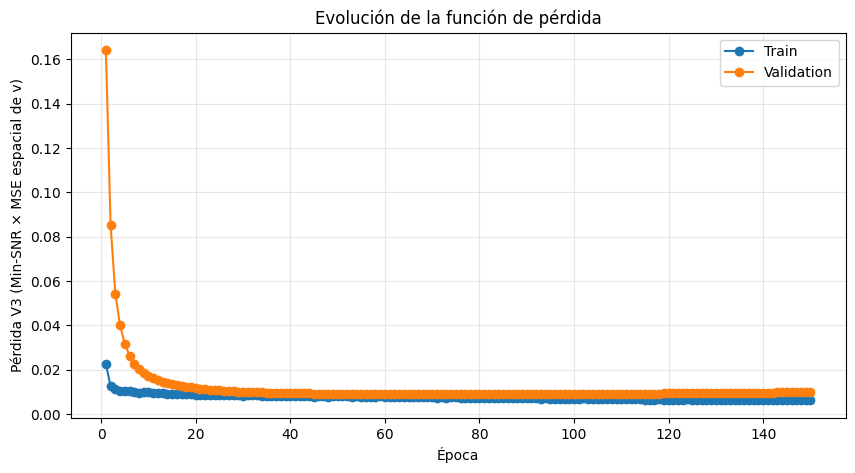

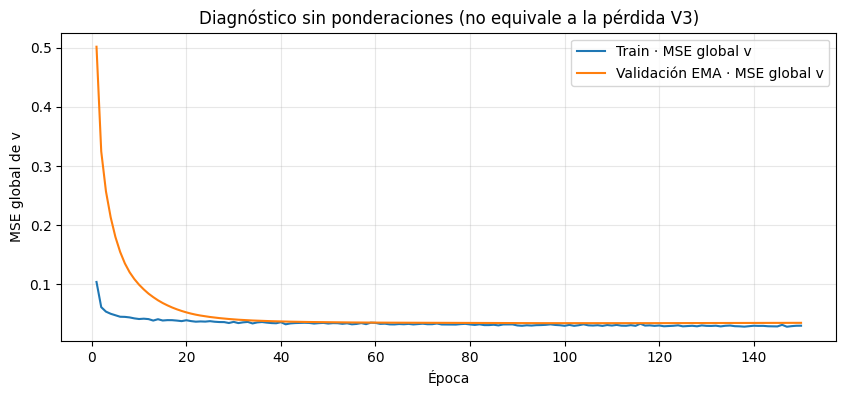

In [23]:
history_path = LOG_DIR / "history.csv"
if history_path.exists():
    history_df = pd.read_csv(history_path)

    plt.figure(figsize=(10, 5))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
    plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
    plt.xlabel("Época")
    plt.ylabel("Pérdida V3 (Min-SNR × MSE espacial de v)")
    plt.title("Evolución de la función de pérdida")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    if "train_mse_v_global" in history_df:
        plt.figure(figsize=(10, 4))
        plt.plot(history_df["epoch"], history_df["train_mse_v_global"], label="Train · MSE global v")
        plt.plot(history_df["epoch"], history_df["val_mse_v_global_ema"], label="Validación EMA · MSE global v")
        plt.title("Diagnóstico sin ponderaciones (no equivale a la pérdida V3)")
        plt.xlabel("Época")
        plt.ylabel("MSE global de v")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()
else:
    print("Todavía no existe history.csv")


## 22. Comprobación de checkpoints EMA

Se dispone de un procedimiento opcional para recalcular la pérdida de validación de los checkpoints periódicos.


In [24]:
def list_checkpoint_candidates(
    checkpoint_dir,
):
    checkpoint_dir = Path(
        checkpoint_dir
    )

    candidates = list(
        checkpoint_dir.glob(
            "checkpoint_epoch_*.pt"
        )
    )


    # Evitar evaluar como candidato el archivo
    # que esta misma rutina produce.
    candidates = [
        p
        for p in candidates
        if p.name
        != "best_val_ema.pt"
    ]

    # Eliminar duplicados preservando orden.
    unique = []

    seen = set()

    for path in sorted(
        candidates,
        key=lambda p: p.name,
    ):
        resolved = str(
            path.resolve()
        )

        if resolved not in seen:
            seen.add(
                resolved
            )
            unique.append(
                path
            )

    return unique


@torch.no_grad()
def reevaluate_checkpoints_with_ema(
    checkpoint_dir,
    val_loader,
    ema_model,
):
    candidates = (
        list_checkpoint_candidates(
            checkpoint_dir
        )
    )

    if not candidates:
        raise FileNotFoundError(
            "No hay checkpoints disponibles "
            "para recalibración EMA."
        )

    rows = []

    best_path = None
    best_loss = float(
        "inf"
    )

    for path in tqdm(
        candidates,
        desc="Reevaluando checkpoints EMA",
    ):
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

        config_saved = checkpoint.get("config", {})
        comprobar_configuracion_checkpoint(config_saved, str(path))

        ema_model.load_state_dict(
            checkpoint[
                "ema_state_dict"
            ]
        )

        ema_model.to(
            DEVICE
        )

        val_metrics = validate_one_epoch(ema_model, val_loader)
        val_loss_ema = val_metrics["loss_weighted_v"]

        epoch = int(
            checkpoint.get(
                "epoch",
                -1,
            )
        )

        rows.append({
            "checkpoint":
                str(path),
            "checkpoint_name":
                path.name,
            "epoch":
                epoch,
            "val_loss_ema_shared":
                float(
                    val_loss_ema
                ),
            "shared_split_csv":
                str(
                    COMMON_SPLIT_CSV
                ),
        })

        if (
            val_loss_ema
            < best_loss
        ):
            best_loss = (
                val_loss_ema
            )

            best_path = (
                path
            )

    results_df = (
        pd.DataFrame(
            rows
        )
        .sort_values(
            [
                "val_loss_ema_shared",
                "epoch",
            ]
        )
        .reset_index(
            drop=True
        )
    )

    results_path = (
        LOG_DIR
        / "checkpoint_ema_recalibration.csv"
    )

    results_df.to_csv(
        results_path,
        index=False,
    )

    destination = (
        CHECKPOINT_DIR
        / "best_val_ema.pt"
    )

    shutil.copy2(
        best_path,
        destination,
    )

    print(
        "Mejor checkpoint EMA:",
        best_path,
    )

    print(
        "Validation loss EMA:",
        best_loss,
    )

    print(
        "Copiado como:",
        destination,
    )

    print(
        "Tabla de recalibración:",
        results_path,
    )

    return (
        results_df,
        destination,
    )


BEST_EMA_CHECKPOINT = (
    CHECKPOINT_DIR
    / "best_val_ema.pt"
)

if FORCE_REEVALUATE_EMA_CHECKPOINTS or (
    not BEST_EMA_CHECKPOINT.exists() and bool(list_checkpoint_candidates(CHECKPOINT_DIR))
):
    ema_recalibration_df, BEST_EMA_CHECKPOINT = (
        reevaluate_checkpoints_with_ema(
            CHECKPOINT_DIR,
            val_loader,
            ema_model,
        )
    )

    display(
        ema_recalibration_df.head(
            10
        )
    )

else:
    print(
        "Ya existe un checkpoint "
        "seleccionado mediante EMA:"
    )
    print(
        BEST_EMA_CHECKPOINT
    )


Ya existe un checkpoint seleccionado mediante EMA:
K:\Tesis\Github\results\OE3\difusion_gaussiana_v3\snr5_W1,2,6\checkpoints\best_val_ema.pt


## 23. Recuperación del modelo para inferencia

Se cargan los parámetros EMA del checkpoint seleccionado para realizar la generación sintética.


In [25]:
GENERATION_CHECKPOINT = (
    CHECKPOINT_DIR
    / "best_val_ema.pt"
)

if not GENERATION_CHECKPOINT.exists():
    raise FileNotFoundError(
        "No existe best_val_ema.pt.\n"
        "Se requiere el archivo en results/OE3/difusion_gaussiana_v3/<modelo>/checkpoints/."
    )

inference_checkpoint = torch.load(
    GENERATION_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

inference_config = inference_checkpoint.get("config", {})
comprobar_configuracion_checkpoint(inference_config, str(GENERATION_CHECKPOINT))

ema_model.load_state_dict(
    inference_checkpoint[
        "ema_state_dict"
    ]
)

ema_model.eval()

print(
    "Checkpoint de inferencia:",
    GENERATION_CHECKPOINT,
)

print(
    "Época:",
    inference_checkpoint["epoch"],
)

print(
    "Selección:",
    inference_checkpoint.get(
        "checkpoint_selection",
        "checkpoint legado recalibrado externamente",
    ),
)


Checkpoint de inferencia: K:\Tesis\Github\results\OE3\difusion_gaussiana_v3\snr5_W1,2,6\checkpoints\best_val_ema.pt
Época: 83
Selección: ema_validation_loss


## 24. Generación condicionada por máscaras externas

Se preparan las máscaras sintéticas y sus transformadas EDT para el muestreo condicionado.


In [26]:
def prepare_external_mask(mask_path, image_size, edt_radius):
    mask_img = Image.open(mask_path).convert("L")
    mask_img = mask_img.resize(
        (image_size, image_size),
        resample=Image.Resampling.NEAREST,
    )
    mask_np = (np.asarray(mask_img, dtype=np.float32) > MASK_THRESHOLD).astype(np.float32)

    if mask_np.sum() == 0:
        raise ValueError(f"La máscara está vacía después del preprocesamiento: {mask_path}")

    edt_np = compute_signed_edt(mask_np, edt_radius)

    mask_tensor = torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0).to(DEVICE)
    edt_tensor = torch.from_numpy(edt_np).unsqueeze(0).unsqueeze(0).to(DEVICE)
    return mask_tensor, edt_tensor


@torch.no_grad()
def generate_from_synthetic_mask(
    mask_path,
    tumor_code,
    plane_code,
    sampler="ddim",
    ddim_steps=DDIM_STEPS_PRODUCTION,
    ddim_eta=DDIM_ETA_PRODUCTION,
    seed=SEED,
):
    tumor_code = tumor_code.lower()
    plane_code = plane_code.lower()

    if tumor_code not in TUMOR_TO_ID:
        raise ValueError(f"tumor_code inválido: {tumor_code}")
    if plane_code not in PLANE_TO_ID:
        raise ValueError(f"plane_code inválido: {plane_code}")

    mask, edt = prepare_external_mask(mask_path, IMAGE_SIZE, EDT_RADIUS)
    tumor_id = torch.tensor([TUMOR_TO_ID[tumor_code]], device=DEVICE, dtype=torch.long)
    plane_id = torch.tensor([PLANE_TO_ID[plane_code]], device=DEVICE, dtype=torch.long)

    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    initial_noise = torch.randn(
        (1, 1, IMAGE_SIZE, IMAGE_SIZE),
        device=DEVICE,
        generator=generator,
    )

    if sampler.lower() == "ddim":
        image = sample_ddim(
            ema_model,
            mask,
            edt,
            tumor_id,
            plane_id,
            num_steps=ddim_steps,
            eta=ddim_eta,
            initial_noise=initial_noise,
            generator=generator,
            show_progress=True,
        )
    elif sampler.lower() == "ddpm":
        image = sample_ddpm(
            ema_model,
            mask,
            edt,
            tumor_id,
            plane_id,
            initial_noise=initial_noise,
            generator=generator,
            show_progress=True,
        )
    else:
        raise ValueError("sampler debe ser 'ddim' o 'ddpm'.")

    return image, mask, edt


# EJEMPLO — reemplazar la ruta por una máscara real generada por OE2:
# example_mask = OE2_SYNTHETIC_MASK_DIR / "synthetic_00001_gl_ax.png"
# generated, mask, edt = generate_from_synthetic_mask(
#     example_mask,
#     tumor_code="gl",
#     plane_code="ax",
#     sampler="ddim",
#     ddim_steps=100,
#     seed=123,
# )
# plt.imshow(generated[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
# plt.axis("off")
# plt.show()


## 25. Inventario de máscaras sintéticas

Se identifican las máscaras aceptadas procedentes de OE2 y sus condiciones de generación.


In [27]:
CONDITION_DIR_RE = re.compile(
    r"^(gl|me|pi)_(ax|co|sa)$",
    flags=re.IGNORECASE,
)


def parse_synthetic_conditions_from_parent(
    path,
):
    condition_dir = (
        path.parent.name.lower()
    )

    match = CONDITION_DIR_RE.match(
        condition_dir
    )

    if match is None:
        raise ValueError(
            "Subcarpeta de condición no "
            f"reconocida: {path.parent}. "
            "Se esperaba una de gl_ax, gl_co, "
            "gl_sa, me_ax, me_co, me_sa, "
            "pi_ax, pi_co o pi_sa."
        )

    tumor_code, plane_code = (
        match.groups()
    )

    return (
        tumor_code.lower(),
        plane_code.lower(),
    )


def normalize_smoothing_code(
    smoothing_code,
):
    if smoothing_code is None:
        return None

    text = str(
        smoothing_code
    ).lower().replace(
        "suavizado",
        "",
    ).strip()

    if text.isdigit():
        text = text.zfill(
            3
        )

    if text not in OE2_SIGMA_BY_CODE:
        raise ValueError(
            "Código de suavizado inválido. "
            f"Disponibles: {sorted(OE2_SIGMA_BY_CODE)}"
        )

    return text


def resolve_oe2_mask_source(
    weight_code,
    mask_variant,
    smoothing_code=None,
):
    weight_code = str(
        weight_code
    ).zfill(
        2
    )

    if (
        weight_code
        not in OE2_ROI_OUTSIDE_WEIGHT_VALUES
    ):
        raise ValueError(
            "weight_code debe ser "
            "'01', '05' o '10'."
        )

    weight_folder = (
        f"roiOE1_peso{weight_code}"
    )

    run_root = (
        RESULTS_OE2 / "difusion_bernoulli" / "final" / weight_folder
    )

    final_root = (
        run_root
        / "mascaras_sinteticas_finales"
    )

    if mask_variant == "sin_suavizado":
        source_dir = (
            final_root
            / "sin_suavizado"
            / "aceptadas"
        )

        sigma = None
        smoothing_code = None
        variant_tag = Path(
            "sin_suavizado"
        )

    elif mask_variant == "suavizado":
        smoothing_code = (
            normalize_smoothing_code(
                smoothing_code
            )
        )

        sigma = (
            OE2_SIGMA_BY_CODE[
                smoothing_code
            ]
        )

        source_dir = (
            final_root
            / f"suavizado{smoothing_code}"
            / "aceptadas"
        )

        variant_tag = Path(
            f"suavizado{smoothing_code}"
        )

    else:
        raise ValueError(
            "mask_variant debe ser "
            "'sin_suavizado' o 'suavizado'."
        )

    provenance = {
        "weight_code":
            weight_code,
        "weight_folder":
            weight_folder,
        "roi_outside_weight":
            OE2_ROI_OUTSIDE_WEIGHT_VALUES[
                weight_code
            ],
        "mask_variant":
            mask_variant,
        "smoothing_code":
            smoothing_code,
        "gaussian_sigma":
            sigma,
        "variant_tag":
            variant_tag,
    }

    return (
        source_dir,
        provenance,
    )


def discover_oe2_synthetic_masks(
    mask_root,
):
    mask_root = Path(
        mask_root
    )

    if not mask_root.exists():
        raise FileNotFoundError(
            "No existe el directorio "
            f"del OE2: {mask_root}"
        )

    existing_condition_dirs = {
        p.name.lower()
        for p in mask_root.iterdir()
        if (
            p.is_dir()
            and CONDITION_DIR_RE.match(
                p.name.lower()
            )
        )
    }

    missing_dirs = (
        OE2_EXPECTED_CONDITION_DIRS
        - existing_condition_dirs
    )

    if missing_dirs:
        raise RuntimeError(
            "Faltan subcarpetas de "
            "condición en el OE2: "
            f"{sorted(missing_dirs)}"
        )

    mask_paths = []

    for condition_dir in sorted(
        existing_condition_dirs
    ):
        folder = (
            mask_root
            / condition_dir
        )

        mask_paths.extend(
            sorted(
                folder.glob(
                    "*.png"
                )
            )
        )

    if not mask_paths:
        raise FileNotFoundError(
            "No se encontraron máscaras PNG "
            f"dentro de {mask_root}"
        )

    return mask_paths


class SyntheticMaskDataset(Dataset):
    def __init__(
        self,
        mask_paths,
        image_size,
        edt_radius,
    ):
        self.records = []

        for path in mask_paths:
            path = Path(
                path
            )

            (
                tumor_code,
                plane_code,
            ) = (
                parse_synthetic_conditions_from_parent(
                    path
                )
            )

            self.records.append({
                "mask_path":
                    str(path),
                "tumor_code":
                    tumor_code,
                "plane_code":
                    plane_code,
            })

        self.image_size = (
            image_size
        )

        self.edt_radius = (
            edt_radius
        )

    def __len__(
        self
    ):
        return len(
            self.records
        )

    def __getitem__(
        self,
        idx,
    ):
        record = (
            self.records[
                idx
            ]
        )

        path = Path(
            record[
                "mask_path"
            ]
        )

        mask_img = (
            Image.open(
                path
            ).convert(
                "L"
            )
        )

        mask_img = mask_img.resize(
            (
                self.image_size,
                self.image_size,
            ),
            resample=(
                Image.Resampling.NEAREST
            ),
        )

        mask_np = (
            np.asarray(
                mask_img,
                dtype=np.float32,
            )
            > MASK_THRESHOLD
        ).astype(
            np.float32
        )

        if mask_np.sum() == 0:
            raise ValueError(
                "Máscara sintética vacía: "
                f"{path}"
            )

        edt_np = compute_signed_edt(
            mask_np,
            self.edt_radius,
        )

        return {
            "mask":
                torch.from_numpy(
                    mask_np
                ).unsqueeze(0),

            "edt":
                torch.from_numpy(
                    edt_np
                ).unsqueeze(0),

            "tumor_id":
                torch.tensor(
                    TUMOR_TO_ID[
                        record[
                            "tumor_code"
                        ]
                    ],
                    dtype=torch.long,
                ),

            "plane_id":
                torch.tensor(
                    PLANE_TO_ID[
                        record[
                            "plane_code"
                        ]
                    ],
                    dtype=torch.long,
                ),

            "tumor_code":
                record[
                    "tumor_code"
                ],

            "plane_code":
                record[
                    "plane_code"
                ],

            "mask_path":
                record[
                    "mask_path"
                ],

            "condition_dir":
                path.parent.name,

            "stem":
                path.stem,
        }


def stable_sample_seed(
    base_seed,
    condition_dir,
    stem,
):
    key = (
        f"{condition_dir}/{stem}"
    )

    digest = hashlib.sha1(
        key.encode(
            "utf-8"
        )
    ).hexdigest()

    offset = int(
        digest[:8],
        16,
    )

    # Mantener la seed dentro del rango entero
    # convencional usado por PyTorch.
    return int(
        (
            int(base_seed)
            + offset
        )
        % (2**31 - 1)
    )


def build_sample_generators(
    base_seed,
    condition_dirs,
    stems,
):
    sample_seeds = [
        stable_sample_seed(
            base_seed,
            condition_dir,
            stem,
        )
        for condition_dir, stem in zip(
            condition_dirs,
            stems,
        )
    ]

    generators = [
        torch.Generator(
            device=DEVICE
        ).manual_seed(
            seed
        )
        for seed in sample_seeds
    ]

    return (
        sample_seeds,
        generators,
    )


def format_float_tag(
    value,
):
    text = f"{float(value):g}"

    if "." not in text:
        text += ".0"

    return (
        text
        .replace(
            ".",
            "p",
        )
        .replace(
            "-",
            "m",
        )
    )


### Configuraciones DDIM

Se consideran ocho combinaciones de 50, 100, 200 y 300 pasos con $\eta\in\{0,0.2\}$, utilizando 100 máscaras por cada una de las nueve condiciones.


In [28]:
# Ocho configuraciones DDIM con las mismas máscaras y semillas.
DDIM_CONFIGS = [(50, 0.0), (50, 0.2), (100, 0.0),(100,0.2), (200, 0.0), (200, 0.2) , (300, 0.0) , (300, 0.2)]
N_PER_CONDITION = 100
MASK_SELECTION_SEED = 2026
GENERATION_BASE_SEED = 10000
GENERATION_BATCH_SIZE = 1  # Precaución por atención a 64×64; puede elevarse tras prueba.
RUN_DDIM_GENERATION = False  # Activación explícita de la generación masiva.

assert len(DDIM_CONFIGS) == 8 and N_PER_CONDITION == 100
assert len(OE2_EXPECTED_CONDITION_DIRS) == 9

# Guardar plan reproducible, independiente del hash de entrenamiento.
plan = {
    "version": "OE3_V3", "checkpoint": str(GENERATION_CHECKPOINT),
    "training_config_hash": TRAINING_CONFIG_HASH,
    "mask_source": str(OE2_SYNTHETIC_MASK_DIR),
    "mask_selection_seed": MASK_SELECTION_SEED, "base_seed": GENERATION_BASE_SEED,
    "n_per_condition": N_PER_CONDITION,
    "ddim_configs": [{"steps": s, "eta": e} for s, e in DDIM_CONFIGS],
    "generation_batch_size": GENERATION_BATCH_SIZE,
}
with open(CONFIG_DIR / "plan_generacion_ddim.json", "w", encoding="utf-8") as f:
    json.dump(plan, f, ensure_ascii=False, indent=2)
print(json.dumps(plan, ensure_ascii=False, indent=2))


{
  "version": "OE3_V3",
  "checkpoint": "K:\\Tesis\\Github\\results\\OE3\\difusion_gaussiana_v3\\snr5_W1,2,6\\checkpoints\\best_val_ema.pt",
  "training_config_hash": "608f8462",
  "mask_source": "K:\\Tesis\\Github\\results\\OE2\\difusion_bernoulli\\final\\roiOE1_peso10\\mascaras_sinteticas_finales\\suavizado200\\aceptadas",
  "mask_selection_seed": 2026,
  "base_seed": 10000,
  "n_per_condition": 100,
  "ddim_configs": [
    {
      "steps": 50,
      "eta": 0.0
    },
    {
      "steps": 50,
      "eta": 0.2
    },
    {
      "steps": 100,
      "eta": 0.0
    },
    {
      "steps": 100,
      "eta": 0.2
    },
    {
      "steps": 200,
      "eta": 0.0
    },
    {
      "steps": 200,
      "eta": 0.2
    },
    {
      "steps": 300,
      "eta": 0.0
    },
    {
      "steps": 300,
      "eta": 0.2
    }
  ],
  "generation_batch_size": 1
}


### Selección reproducible de máscaras y generación incremental

Se fija la selección de máscaras y se habilita la reanudación de los archivos generados.


In [29]:
def select_same_oe2_masks(n_per_condition=None):
    if n_per_condition is None:
        n_per_condition = N_PER_CONDITION

    root = Path(OE2_SYNTHETIC_MASK_DIR)
    if not root.is_dir():
        raise FileNotFoundError(f"No existe el directorio OE2: {root}")

    order_csv = CONFIG_DIR / "orden_completo_mascaras_oe2.csv"
    if not order_csv.exists():
        # Para un experimento nuevo se fija un orden reproducible. Si ya
        # existen imágenes, es obligatorio recuperar el inventario original.
        if any(GENERATION_ROOT.rglob("*_oe3.png")):
            raise FileNotFoundError(
                "Existen imágenes generadas sin el inventario original de máscaras: "
                f"{order_csv}. Recuperar el CSV antes de continuar."
            )
        available = discover_oe2_synthetic_masks(root)
        records = []
        for condition in sorted(OE2_EXPECTED_CONDITION_DIRS):
            group = sorted(p for p in available if p.parent.name == condition)
            if len(group) < n_per_condition:
                raise RuntimeError(f"Faltan máscaras para {condition}")
            generator = np.random.default_rng(
                MASK_SELECTION_SEED + int(hashlib.sha1(condition.encode()).hexdigest()[:8], 16)
            )
            for order, idx in enumerate(generator.permutation(len(group)), start=1):
                path = group[int(idx)]
                records.append({"condition": condition, "mask_path": str(path),
                                "selection_order": order})
        order_df = pd.DataFrame(records)
        order_df.to_csv(order_csv, index=False)
    else:
        order_df = pd.read_csv(order_csv, keep_default_na=False)
    selected = []

    for condition in sorted(OE2_EXPECTED_CONDITION_DIRS):
        group = order_df.loc[
            order_df["condition"] == condition
        ].sort_values("selection_order")

        # Las rutas antiguas se resuelven por condición y nombre de archivo.
        paths = [root / condition / Path(str(x)).name for x in group["mask_path"]]

        if len(paths) < n_per_condition:
            raise RuntimeError(f"Faltan máscaras para {condition}")

        if any(p.parent != root / condition or not p.is_file()
               for p in paths[:n_per_condition]):
            raise RuntimeError(f"Fuente de máscaras incompatible: {condition}")

        selected.extend(paths[:n_per_condition])

    df = pd.DataFrame([
        {"condition": p.parent.name, "mask_path": str(p), "stem": p.stem}
        for p in selected
    ])

    old_csv = CONFIG_DIR / "seleccion_mascaras_50_por_condicion.csv"
    if old_csv.exists():
        old = pd.read_csv(old_csv, keep_default_na=False)
        prefix = df.groupby("condition", sort=False).head(50).reset_index(drop=True)
        columnas = ["condition", "stem"]
        if not old[columnas].reset_index(drop=True).equals(prefix[columnas]):
            raise RuntimeError("Las primeras 50 máscaras no coinciden con la selección anterior.")

    selected_csv = CONFIG_DIR / f"seleccion_mascaras_{n_per_condition}_por_condicion.csv"
    if selected_csv.exists():
        old = pd.read_csv(selected_csv, keep_default_na=False)
        columnas = ["condition", "stem"]
        if not old[columnas].reset_index(drop=True).equals(df[columnas]):
            raise RuntimeError("La selección de máscaras es incompatible.")
    else:
        df.to_csv(selected_csv, index=False)

    return selected, df


def ddim_config_tag(steps, eta):
    return f"ddim_steps{int(steps)}_eta{format_float_tag(eta)}"


def sha256_file(path, chunk_size=4 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def _atomic_write_dataframe(df, path):
    tmp = Path(str(path) + ".tmp")
    df.to_csv(tmp, index=False)
    tmp.replace(path)


def _atomic_write_image(image_uint8, path):
    path = Path(path)
    tmp = path.with_name(path.stem + ".tmp.png")
    Image.fromarray(image_uint8, mode="L").save(tmp)
    tmp.replace(path)


@torch.no_grad()
def generate_one_ddim_config(steps, eta, selected_paths, checkpoint_sha256):
    """Reanuda por imagen, siempre que el manifiesto coincida con el entrenamiento y la selección."""
    tag = ddim_config_tag(steps, eta)
    out_dir = GENERATION_ROOT / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    manifest_file = out_dir / "generation_manifest.json"
    metadata_file = out_dir / "synthetic_pairs_metadata.csv"
    fingerprint = hashlib.sha256("\n".join(str(p) for p in selected_paths).encode("utf-8")).hexdigest()
    params = {
        "version": "OE3_V3", "tag": tag, "steps": int(steps), "eta": float(eta),
        "seed": GENERATION_BASE_SEED, "image_size": IMAGE_SIZE, "edt_radius": EDT_RADIUS,
        "mask_threshold": MASK_THRESHOLD, "n_per_condition": N_PER_CONDITION,
        "masks_sha256": fingerprint, "checkpoint_sha256": checkpoint_sha256,
        "checkpoint": str(GENERATION_CHECKPOINT),
        "checkpoint_epoch": int(inference_checkpoint["epoch"]),
        "training_config_hash": TRAINING_CONFIG_HASH,
        "mask_root": str(OE2_SYNTHETIC_MASK_DIR),
    }
    if manifest_file.exists():
        with open(manifest_file, encoding="utf-8") as f:
            existing = json.load(f)
        if existing != params:
            # Se permiten traslados del repositorio y ampliaciones de la misma
            # selección, siempre que se verifique la identidad de los casos.
            claves_fijas = (
                "version", "tag", "steps", "eta", "seed", "image_size",
                "edt_radius", "mask_threshold", "checkpoint_sha256", "checkpoint_epoch",
            )
            if any(existing.get(k) != params.get(k) for k in claves_fijas):
                raise RuntimeError(f"Manifiesto incompatible en {out_dir}")
            old_n = int(existing.get("n_per_condition", -1))
            if not 0 < old_n <= N_PER_CONDITION:
                raise RuntimeError(f"Cantidad de máscaras incompatible en {out_dir}")
            expected_old = {
                (p.parent.name, p.stem)
                for condition in sorted(OE2_EXPECTED_CONDITION_DIRS)
                for p in [q for q in selected_paths if q.parent.name == condition][:old_n]
            }
            imagenes_previas = {
                (p.parent.name, p.name[:-len("_oe3.png")])
                for p in out_dir.rglob("*_oe3.png")
            }
            if not imagenes_previas.issubset(expected_old):
                raise RuntimeError(f"Imágenes anteriores incompatibles en {out_dir}")
            if metadata_file.exists():
                anterior = pd.read_csv(metadata_file, keep_default_na=False)
                claves_previas = set(zip(anterior["condition_dir"], anterior["stem"]))
                if not claves_previas.issubset(expected_old):
                    raise RuntimeError(f"Metadatos de máscaras incompatibles en {out_dir}")
                if (not anterior.empty and (
                    anterior["checkpoint_sha256"].astype(str) != checkpoint_sha256
                ).any()):
                    raise RuntimeError(f"Metadatos de checkpoint incompatibles en {out_dir}")
            elif imagenes_previas:
                raise RuntimeError(
                    f"No se puede verificar el origen de las imágenes previas en {out_dir}"
                )
            tmp = manifest_file.with_suffix(".json.tmp")
            with open(tmp, "w", encoding="utf-8") as f:
                json.dump(params, f, indent=2, ensure_ascii=False)
            tmp.replace(manifest_file)
    else:
        if any(out_dir.rglob("*_oe3.png")):
            raise RuntimeError(f"Imágenes existentes sin manifiesto de procedencia: {out_dir}")
        with open(manifest_file, "w", encoding="utf-8") as f:
            json.dump(params, f, indent=2, ensure_ascii=False)

    ds = SyntheticMaskDataset(selected_paths, IMAGE_SIZE, EDT_RADIUS)
    records = []
    pending_indices = []
    for i, item in enumerate(ds.records):
        path = Path(item["mask_path"])
        dest = out_dir / path.parent.name / f"{path.stem}_oe3.png"
        seed = stable_sample_seed(GENERATION_BASE_SEED, path.parent.name, path.stem)
        records.append({
            "version": "OE3_V3", "tumor_code": item["tumor_code"],
            "plane_code": item["plane_code"], "condition_dir": path.parent.name,
            "stem": path.stem, "mask_source": "OE2_final_accepted",
            "mask_path": str(path), "image_path": str(dest),
            "checkpoint": str(GENERATION_CHECKPOINT), "checkpoint_epoch": int(inference_checkpoint["epoch"]),
            "checkpoint_sha256": checkpoint_sha256, "training_config_hash": TRAINING_CONFIG_HASH,
            "oe2_weight_code": OE2_ROI_OUTSIDE_WEIGHT_CODE, "oe2_mask_variant": OE2_MASK_VARIANT,
            "oe2_smoothing_code": OE2_SMOOTHING_CODE, "ddim_steps": int(steps),
            "ddim_eta": float(eta), "base_seed": GENERATION_BASE_SEED,
            "sample_seed": seed, "image_size": IMAGE_SIZE, "edt_radius": EDT_RADIUS,
        })
        if not dest.exists():
            pending_indices.append(i)
    if len(pending_indices) == 0:
        df = pd.DataFrame(records)
        _atomic_write_dataframe(df, metadata_file)
        print(f"{tag}: ya están las {len(df)} imágenes; se omite.")
        return df

    # No se borran las imágenes previamente generadas: apto para reanudación.
    from torch.utils.data import Subset
    loader = DataLoader(Subset(ds, pending_indices), batch_size=GENERATION_BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    progress = tqdm(loader, desc=f"DDIM {steps} pasos, η={eta}")
    completed = 0
    for batch in progress:
        masks = batch["mask"].to(DEVICE, non_blocking=True)
        edts = batch["edt"].to(DEVICE, non_blocking=True)
        tumors = batch["tumor_id"].to(DEVICE, non_blocking=True)
        planes = batch["plane_id"].to(DEVICE, non_blocking=True)
        conditions, stems = list(batch["condition_dir"]), list(batch["stem"])
        seeds, generators = build_sample_generators(GENERATION_BASE_SEED, conditions, stems)
        initial_noise = randn_per_sample((len(stems), 1, IMAGE_SIZE, IMAGE_SIZE),
                                        device=DEVICE, dtype=masks.dtype, generators=generators)
        output = sample_ddim(ema_model, masks, edts, tumors, planes, num_steps=steps, eta=eta,
                             initial_noise=initial_noise, generators=generators, show_progress=False)
        for j, stem in enumerate(stems):
            image_path = out_dir / conditions[j] / f"{stem}_oe3.png"
            image_path.parent.mkdir(parents=True, exist_ok=True)
            image_np = denormalize_image(output[j, 0].detach().cpu()).numpy()
            _atomic_write_image(image_np, image_path)
            completed += 1
        # Guardado incremental tras cada lote; metadatos completos solo para PNG presentes.
        ready = [r for r in records if Path(r["image_path"]).exists()]
        _atomic_write_dataframe(pd.DataFrame(ready), metadata_file)
        progress.set_postfix(generadas=len(ready), faltantes=len(records)-len(ready))
    df = pd.DataFrame(records)
    if len(df) != len(selected_paths) or not all(Path(p).exists() for p in df["image_path"]):
        raise RuntimeError(f"Generación incompleta en {tag}; ejecutar de nuevo para reanudar.")
    _atomic_write_dataframe(df, metadata_file)
    print(f"Completado {tag}: {len(df)} PNG; metadata en {metadata_file}")
    return df


### Generación de imágenes por configuración

Se generan las imágenes sintéticas para las configuraciones habilitadas y se registran sus metadatos.


In [30]:
# La generación masiva se ejecuta únicamente si se habilita el indicador.
if RUN_DDIM_GENERATION:
    if DEVICE.type != "cuda":
        raise RuntimeError("La generación masiva V3 se diseñó para ejecutarse en GPU CUDA.")
    selected_mask_paths, selected_mask_df = select_same_oe2_masks()
    display(selected_mask_df.groupby("condition").size().rename("n_mascaras").reset_index())
    if len(selected_mask_paths) != 9 * N_PER_CONDITION:
        raise AssertionError("Cantidad de máscaras incorrecta")
    print("Calculando huella SHA256 del checkpoint de inferencia...")
    checkpoint_sha256 = sha256_file(GENERATION_CHECKPOINT)
    summaries = []
    for steps, eta in DDIM_CONFIGS:
        start = time.perf_counter()
        df = generate_one_ddim_config(steps, eta, selected_mask_paths, checkpoint_sha256)
        summaries.append({"configuracion": ddim_config_tag(steps, eta), "imagenes": len(df),
                          "n_condiciones": df["condition_dir"].nunique(),
                          "segundos_ejecucion": time.perf_counter()-start,
                          "carpeta": str(GENERATION_ROOT / ddim_config_tag(steps, eta))})
        summary_df = pd.DataFrame(summaries)
        _atomic_write_dataframe(summary_df, LOG_DIR / "resumen_generacion_ddim.csv")
        display(summary_df.tail(1))
    expected_total = len(DDIM_CONFIGS) * 9 * N_PER_CONDITION
    assert len(summaries) == len(DDIM_CONFIGS) and sum(s["imagenes"] for s in summaries) == expected_total
    print(f"Completado: {expected_total} imágenes sintéticas.")
else:
    print("Generación desactivada. Tras entrenar y cargar EMA, fijar RUN_DDIM_GENERATION=True en la celda de configuración DDIM y volver a ejecutar esta celda.")


Generación desactivada. Tras entrenar y cargar EMA, fijar RUN_DDIM_GENERATION=True en la celda de configuración DDIM y volver a ejecutar esta celda.


## 26. Inventario de generación

Se verifica la cantidad de imágenes y la disponibilidad de los archivos de cada configuración.


In [31]:
rows = []
for steps, eta in DDIM_CONFIGS:
    folder = GENERATION_ROOT / ddim_config_tag(steps, eta)
    csv_path = folder / "synthetic_pairs_metadata.csv"
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        n_png = sum(
            1 for r in df.itertuples(index=False)
            if (folder / str(r.condition_dir) / f"{r.stem}_oe3.png").is_file()
        )
        per_condition = df.groupby("condition_dir").size().to_dict()
    else:
        n_png, per_condition = 0, {}
    rows.append({"configuracion": ddim_config_tag(steps, eta), "png_verificados": n_png,
                 "n_condiciones": len(per_condition), "conteos": str(per_condition), "ruta": str(folder)})
status_df = pd.DataFrame(rows)
display(status_df)
print("Total PNG verificados:", status_df["png_verificados"].sum(), "/", 8 * 9 * N_PER_CONDITION)
print("La selección de DDIM se realiza en el notebook de evaluación correspondiente.")


,configuracion,png_verificados,n_condiciones,conteos,ruta
0,ddim_steps50_eta0p0,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...
1,ddim_steps50_eta0p2,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...
2,ddim_steps100_eta0p0,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...
3,ddim_steps100_eta0p2,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...
4,ddim_steps200_eta0p0,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...
5,ddim_steps200_eta0p2,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...
6,ddim_steps300_eta0p0,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...
7,ddim_steps300_eta0p2,900,9,"{'gl_ax': 100, 'gl_co': 100, 'gl_sa': 100, 'me...",K:\Tesis\Github\results\OE3\difusion_gaussiana...


Total PNG verificados: 7200 / 7200
La selección de DDIM se realiza en el notebook de evaluación correspondiente.
